In [1]:
import os

folder_path = 'Data_Files/Juno Data/Fenn'
files_to_import = [f for f in os.listdir(folder_path) if f.startswith('2019092')]

# Example: print the list of files
print(files_to_import)

['2019092_jedi_O+S.d2s', '2019092_jedi_H.d2s', '2019092_jedi_He.d2s', '2019092_jade_e.txt', '2019092_jade_He.txt', '2019092_jade_H.txt', '2019092_jedi_e.d2s', '2019092_jade_O+S.txt']


In [2]:
import numpy as np

import matplotlib.pyplot as plt

for filename in files_to_import:
    file_path = os.path.join(folder_path, filename)
    try:
        # Try loading as a text file (assuming whitespace or comma separated)
        data = np.loadtxt(file_path, delimiter=None)
        plt.figure(figsize=(8, 4))
        plt.title(f"Spectrogram: {filename}")
        plt.xlabel("Time (arbitrary units)")
        plt.ylabel("Frequency (arbitrary units)")
        plt.specgram(data, NFFT=256, Fs=1, noverlap=128)
        plt.colorbar(label='Intensity (dB)')
        plt.show()
    except Exception as e:
        print(f"Could not process {filename}: {e}")

Could not process 2019092_jedi_O+S.d2s: could not convert string '[00]000293<?xml' to float64 at row 0, column 1.
Could not process 2019092_jedi_H.d2s: could not convert string '[00]000292<?xml' to float64 at row 0, column 1.
Could not process 2019092_jedi_He.d2s: could not convert string '[00]000294<?xml' to float64 at row 0, column 1.
Could not process 2019092_jade_e.txt: could not convert string '2019-04-02/17:00:22' to float64 at row 0, column 1.
Could not process 2019092_jade_He.txt: could not convert string '2019-04-02/17:00:16' to float64 at row 0, column 1.
Could not process 2019092_jade_H.txt: could not convert string '2019-04-02/17:00:16' to float64 at row 0, column 1.
Could not process 2019092_jedi_e.d2s: could not convert string '[00]000292<?xml' to float64 at row 0, column 1.
Could not process 2019092_jade_O+S.txt: could not convert string '2019-04-02/17:00:16' to float64 at row 0, column 1.


In [7]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import io

# ————————————————————————————————
# (1) Parsers, adapted to accept filenames
# ————————————————————————————————

def parse_txt_file(filepath):
    # Read header and data
    with open(filepath) as f:
        header = f.readline().lstrip("# ").split()
    # extract numeric energy values
    energies = [float(x) for x in header if re.match(r'^[\d\.E\+\-]+$', x)]
    # read rest of file into DataFrame
    df = pd.read_csv(filepath, 
                     delim_whitespace=True, 
                     comment='#', 
                     header=None)
    times = pd.to_datetime(df[0], format='%Y-%m-%d/%H:%M:%S')
    data = df.iloc[:, 1:].values.T
    return times, energies, data

def parse_d2s_file(filepath):
    txt = open(filepath).read()
    # get the yTags string
    ytags = re.search(r'yTags="([^"]+)"', txt).group(1)
    energies = [float(v) for v in ytags.split(',')]
    # extract lines beginning with ':01:'
    lines = [L for L in txt.splitlines() if L.startswith(':01:')]
    times, values = [], []
    for L in lines:
        parts = L.strip().lstrip(':01:').split()
        times.append(pd.to_datetime(parts[0]))
        values.append([float(v) for v in parts[1:]])
    data = np.array(values).T
    return times, energies, data

# ————————————————————————————————
# (2) Loop over your files and plot
# ————————————————————————————————

# adjust the pattern as needed:
txt_files = glob.glob('Data_Files/Juno Data/Fenn/2019092*.txt')
d2s_files = glob.glob('Data_Files/Juno Data/Fenn/2019092*.d2s')

print(txt_files)
print(d2s_files)
for f in txt_files:
    t, E, D = parse_txt_file(f)
    plt.figure(figsize=(6,4))
    plt.pcolormesh(t, E, D)
    plt.yscale('log')
    plt.title(f'Spectrogram (TXT) — {f}')
    plt.xlabel('Time'); plt.ylabel('Energy (eV)')
    plt.colorbar(label='Intensity')
    plt.tight_layout()

for f in d2s_files:
    t, E, D = parse_d2s_file(f)
    plt.figure(figsize=(6,4))
    plt.pcolormesh(t, E, D)
    plt.yscale('log')
    plt.title(f'Spectrogram (D2S) — {f}')
    plt.xlabel('Time'); plt.ylabel('Energy (keV)')
    plt.colorbar(label='Flux')
    plt.tight_layout()

plt.show()


['Data_Files/Juno Data/Fenn/2019092_jade_e.txt', 'Data_Files/Juno Data/Fenn/2019092_jade_He.txt', 'Data_Files/Juno Data/Fenn/2019092_jade_H.txt', 'Data_Files/Juno Data/Fenn/2019092_jade_O+S.txt']
['Data_Files/Juno Data/Fenn/2019092_jedi_O+S.d2s', 'Data_Files/Juno Data/Fenn/2019092_jedi_H.d2s', 'Data_Files/Juno Data/Fenn/2019092_jedi_He.d2s', 'Data_Files/Juno Data/Fenn/2019092_jedi_e.d2s']


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_7165/1485898234.py:19: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(filepath,


EmptyDataError: No columns to parse from file

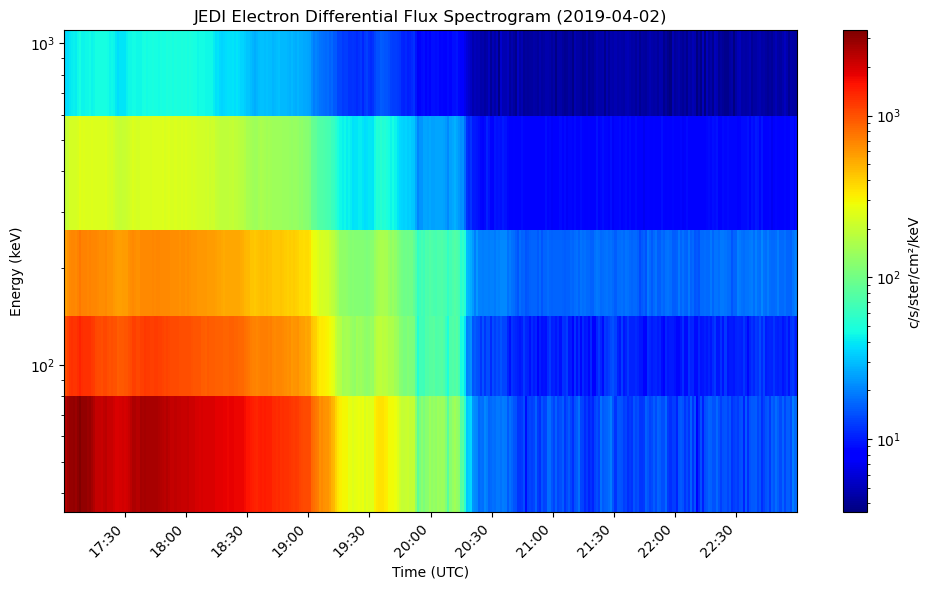

In [18]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates

# File path
fn = 'Data_Files/Juno Data/Fenn/2019092_jedi_e.d2s'

# 1) Read the file
with open(fn, 'r') as f:
    lines = f.readlines()

# 2) Extract energy bin centers
yt_line = next(l for l in lines if 'yTags=' in l)
tags_str = re.search(r'yTags="([^"]+)"', yt_line).group(1)
energies = np.array([float(x) for x in tags_str.split(',')])

# 3) Parse data lines
data_lines = [L for L in lines if L.startswith(':01:')]
times = []
values = []
for L in data_lines:
    parts = L.strip().split()
    ts = parts[0][4:]  
    times.append(pd.to_datetime(ts))
    values.append([float(x) for x in parts[1:]])

# 4) Build arrays
times = np.array(times, dtype='datetime64[ms]')
spec  = np.array(values, dtype=float)

# —– NEW: grab observation date for title —–
obs_date = pd.to_datetime(times[0]).strftime('%Y-%m-%d')

# 5) Plot spectrogram
fig, ax = plt.subplots(figsize=(10,6))
pcm = ax.pcolormesh(times, energies, spec.T, norm=LogNorm(), cmap='jet')

# —– NEW: format x-axis as HH:MM, every 5 minutes —–
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=30))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax.set_xlabel('Time (UTC)')
ax.set_ylabel('Energy (keV)')
ax.set_yscale('log')
ax.set_title(f'JEDI Electron Differential Flux Spectrogram ({obs_date})')

cbar = fig.colorbar(pcm, ax=ax, label='c/s/ster/cm²/keV')
plt.tight_layout()
plt.show()


None


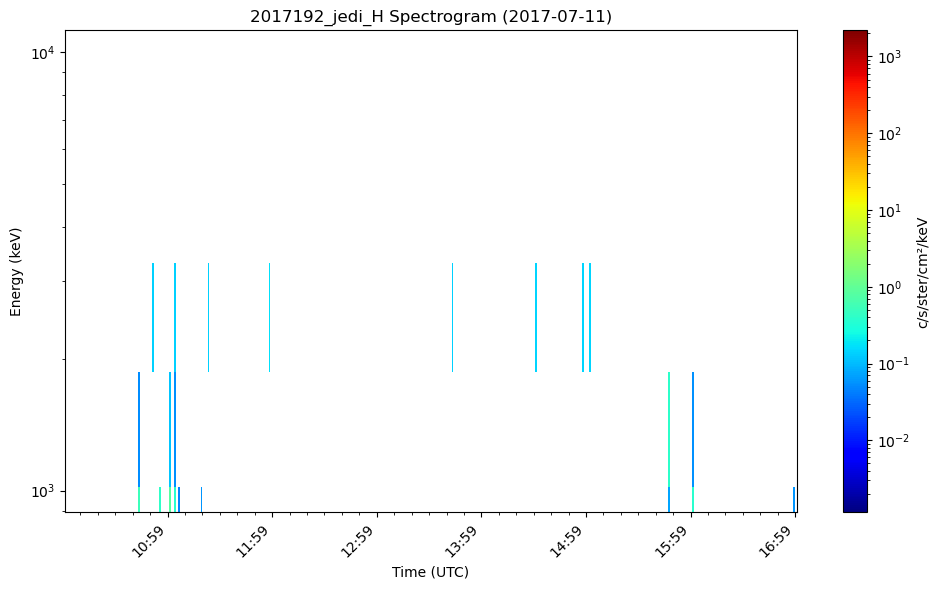

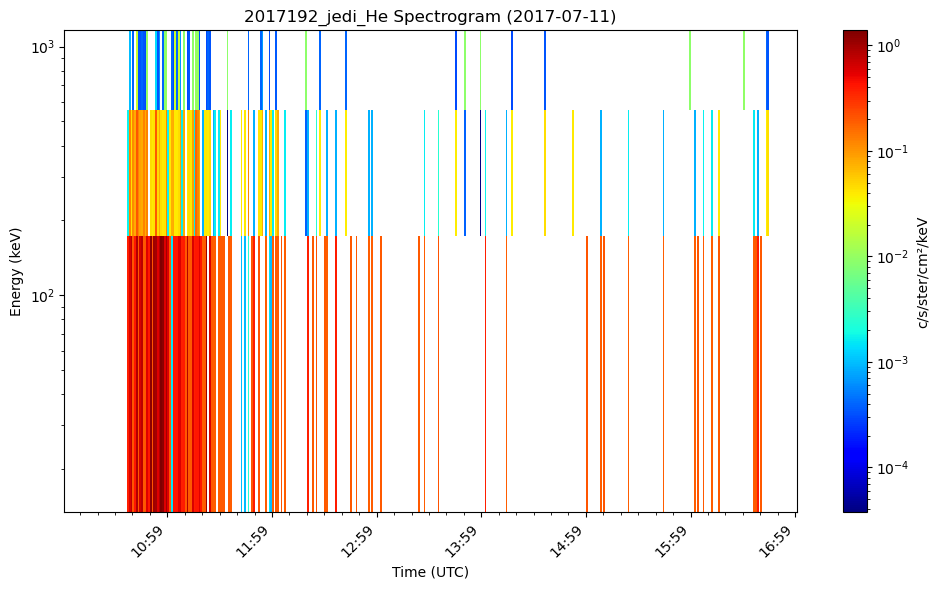

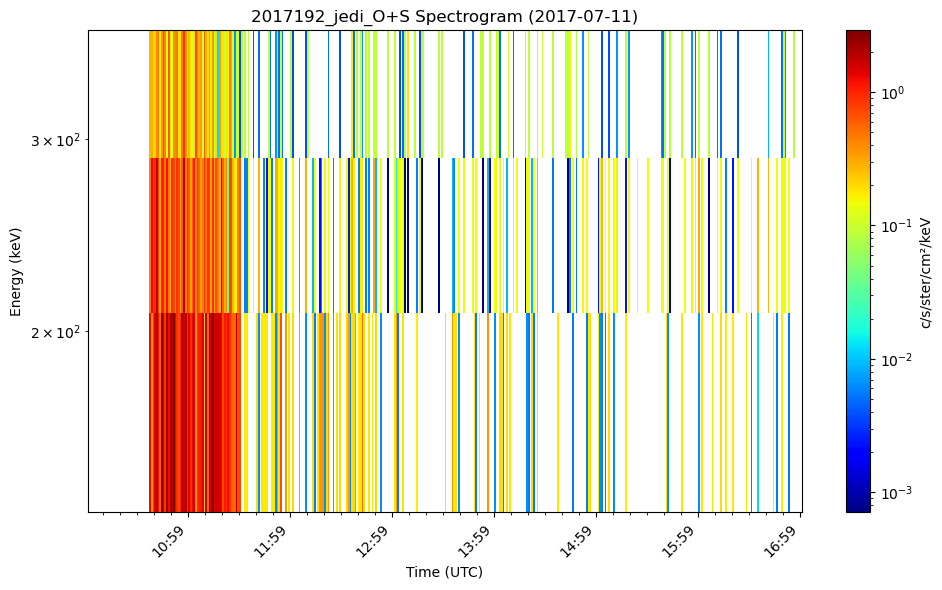

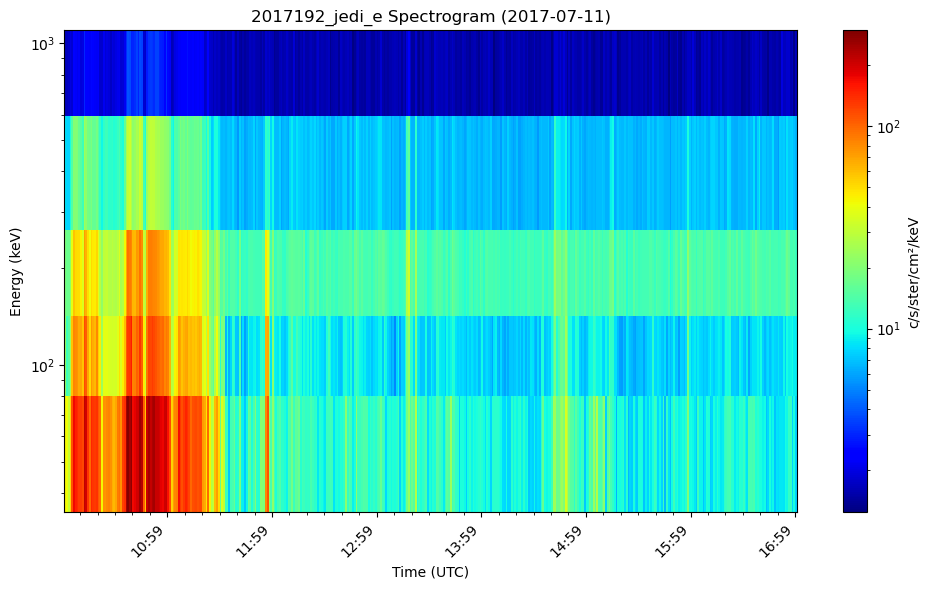

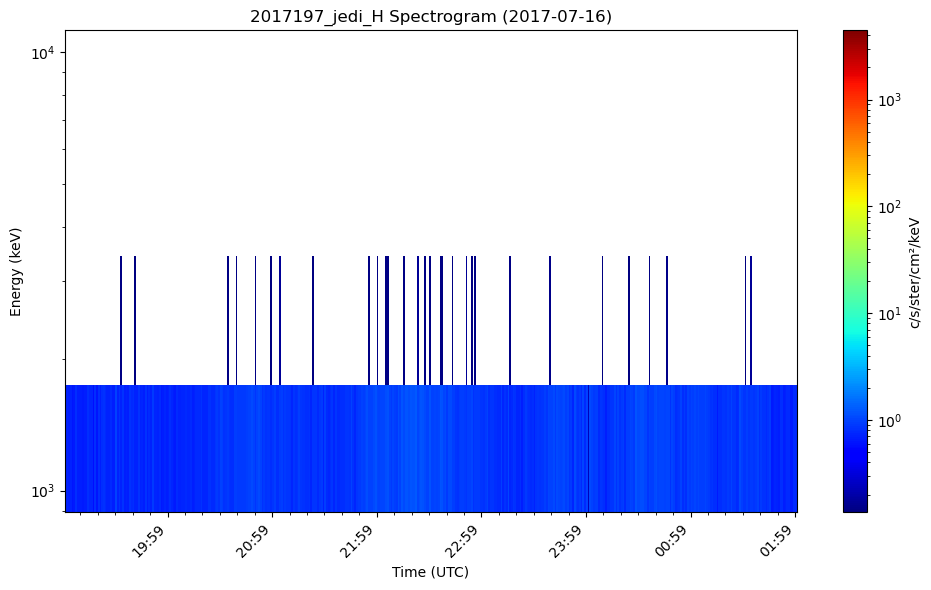

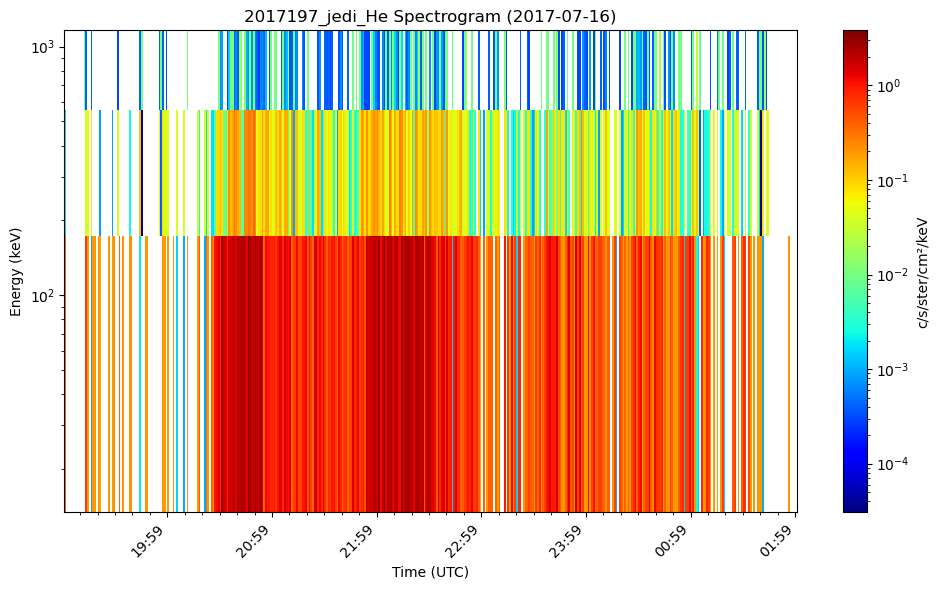

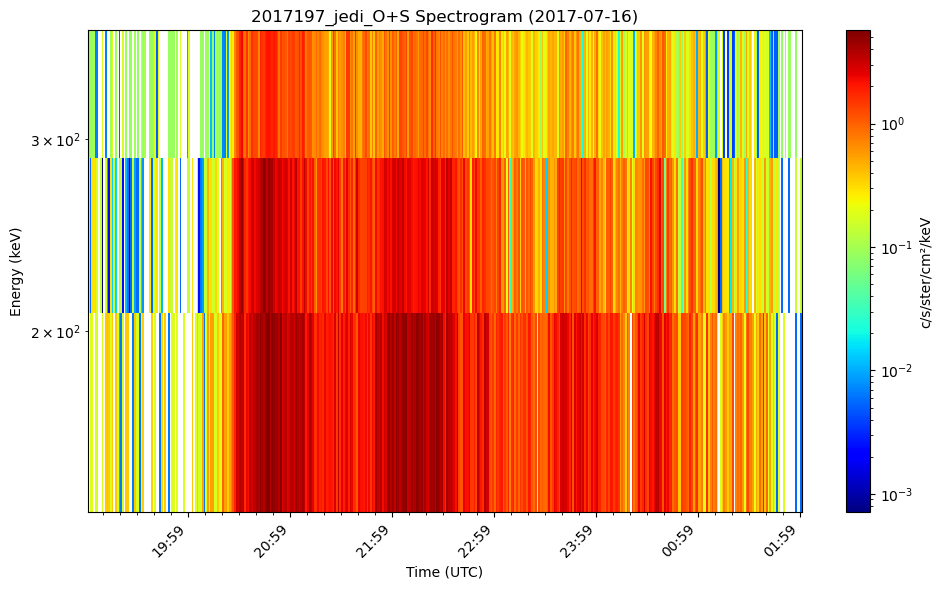

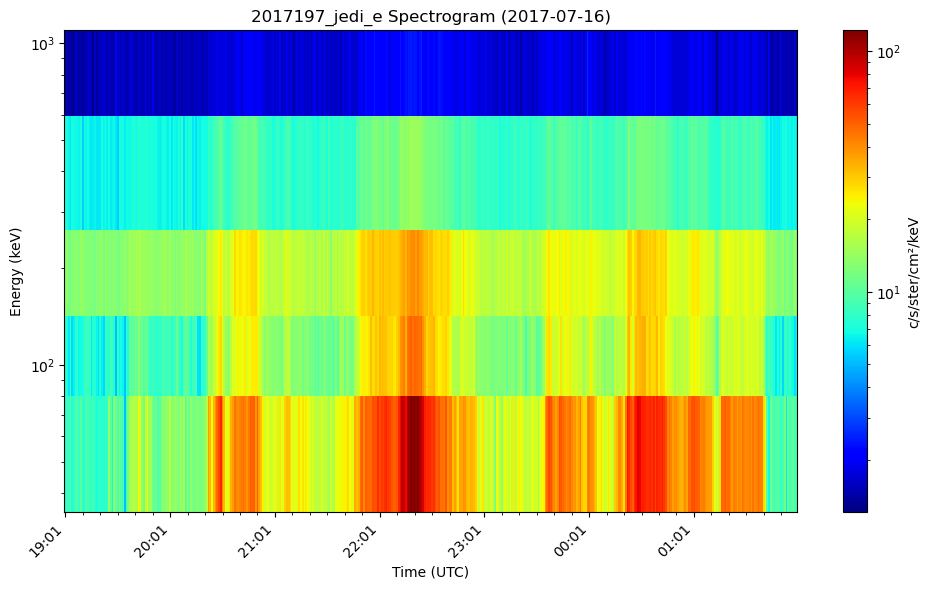

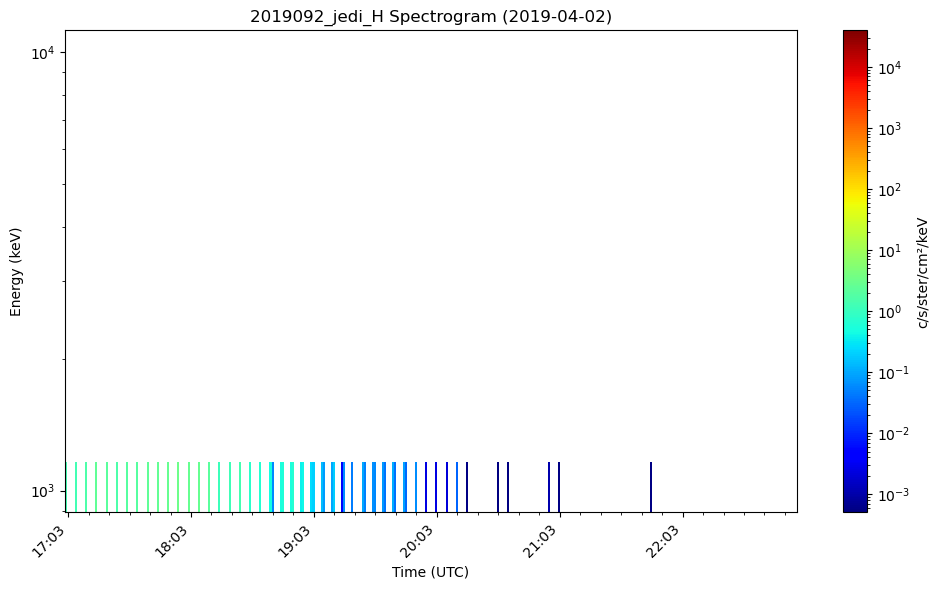

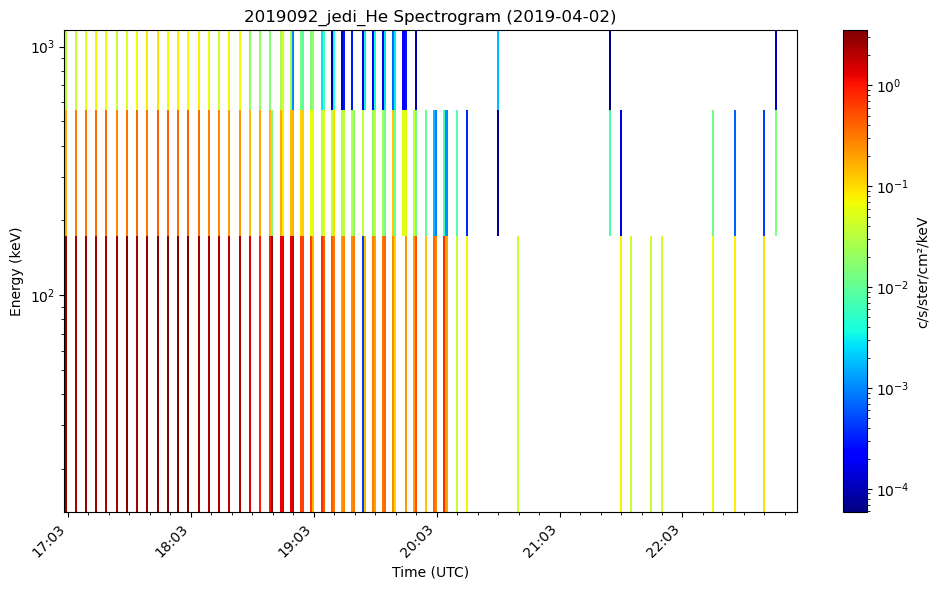

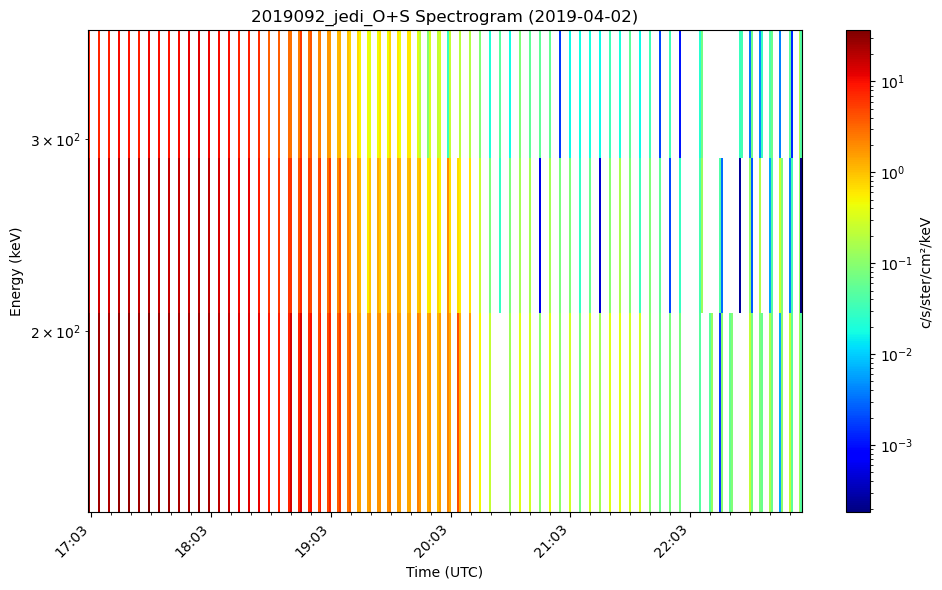

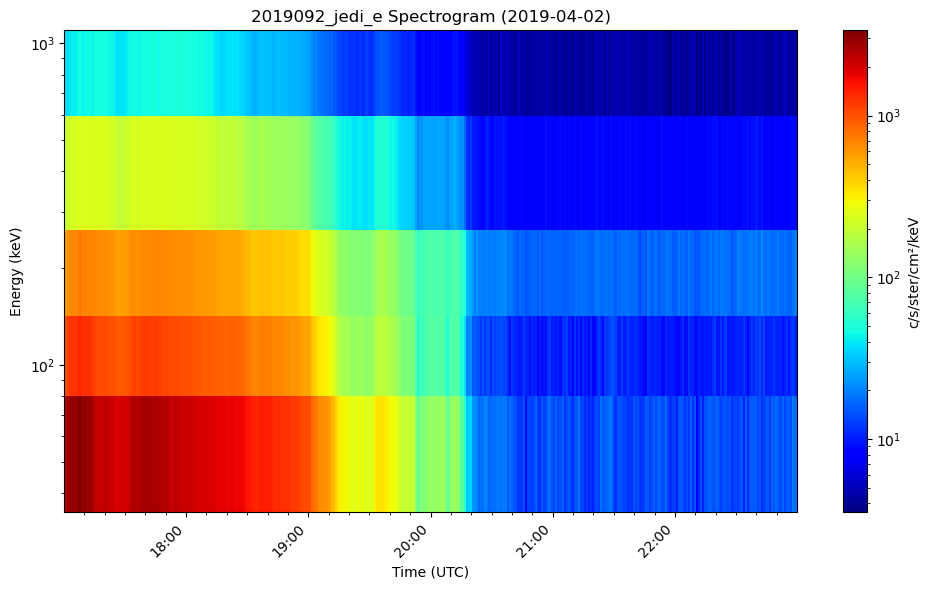

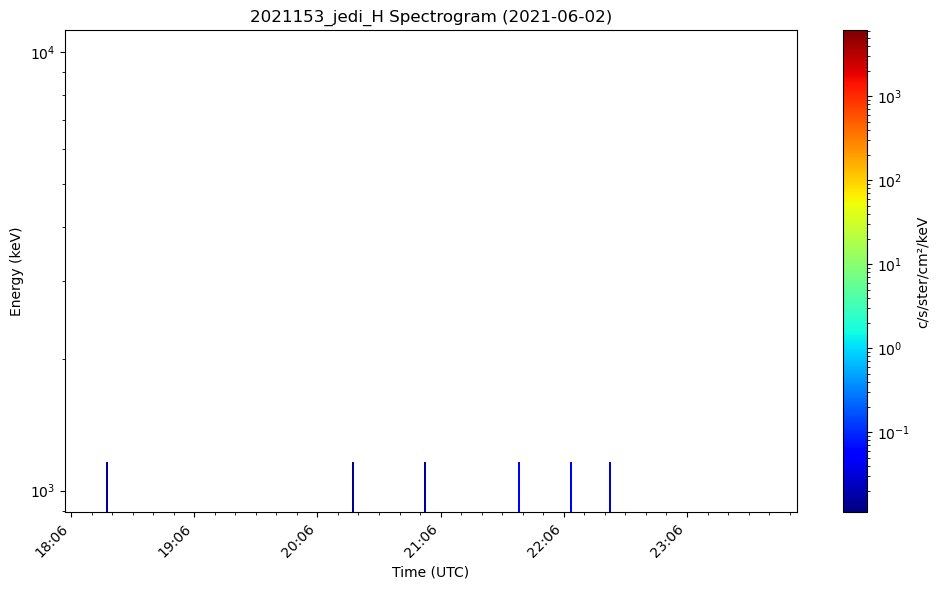

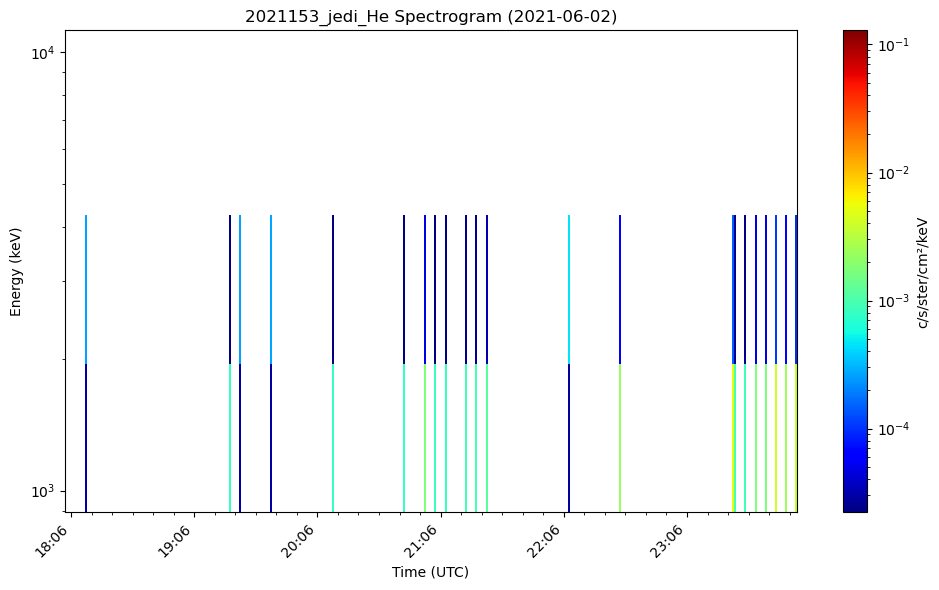

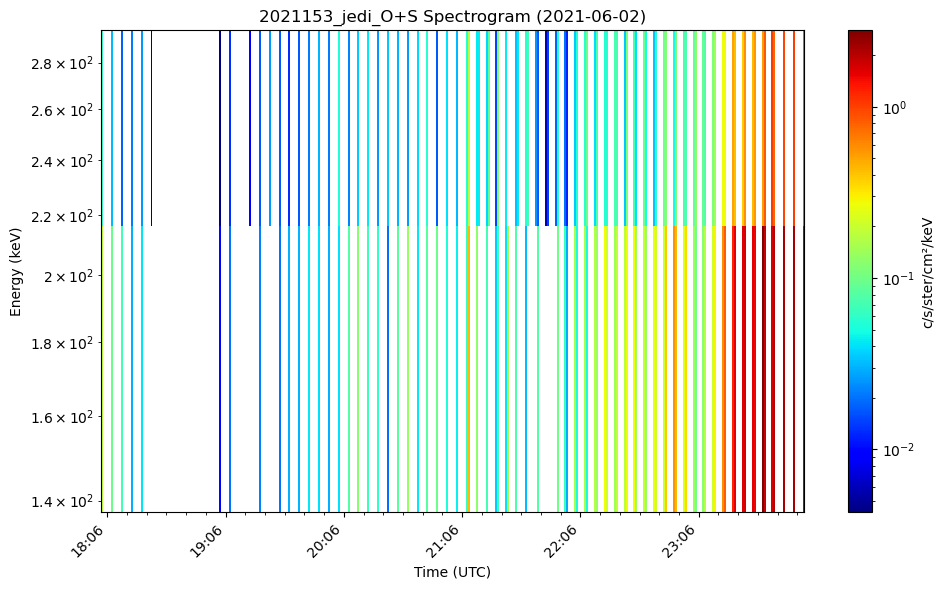

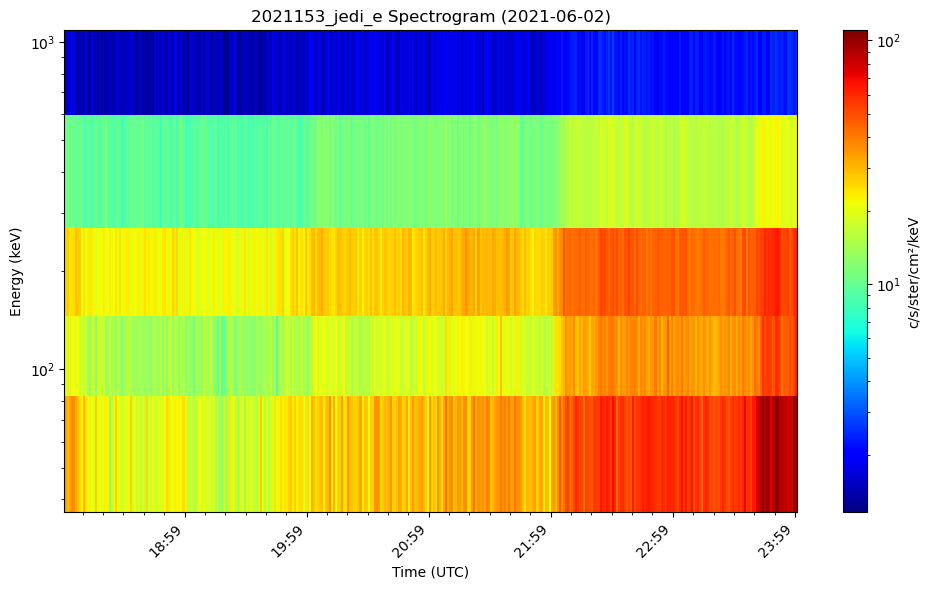

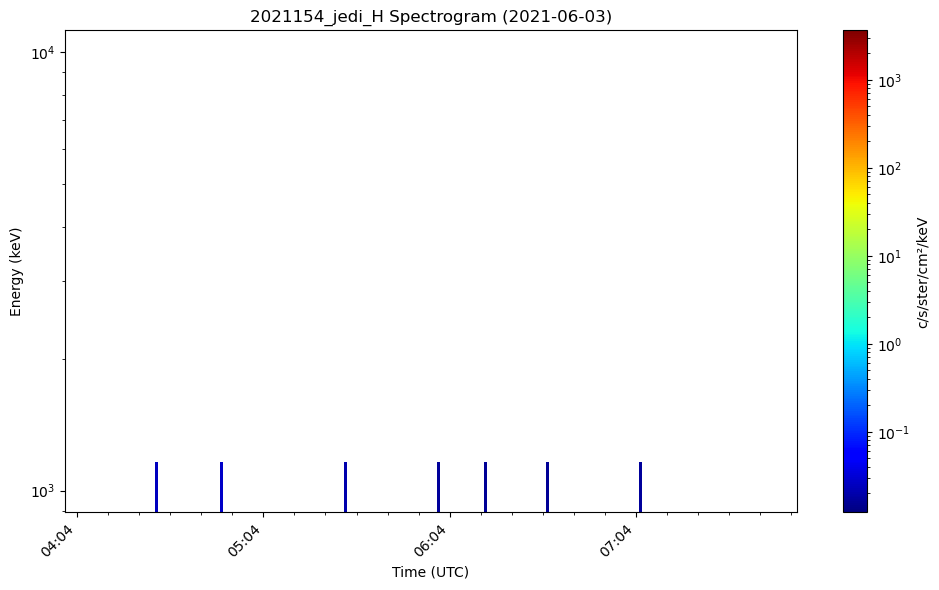

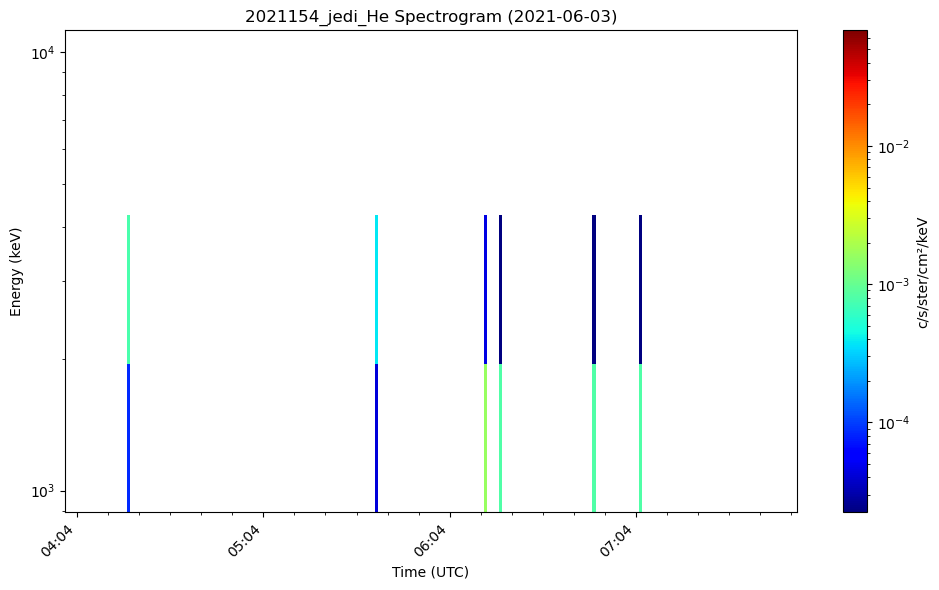

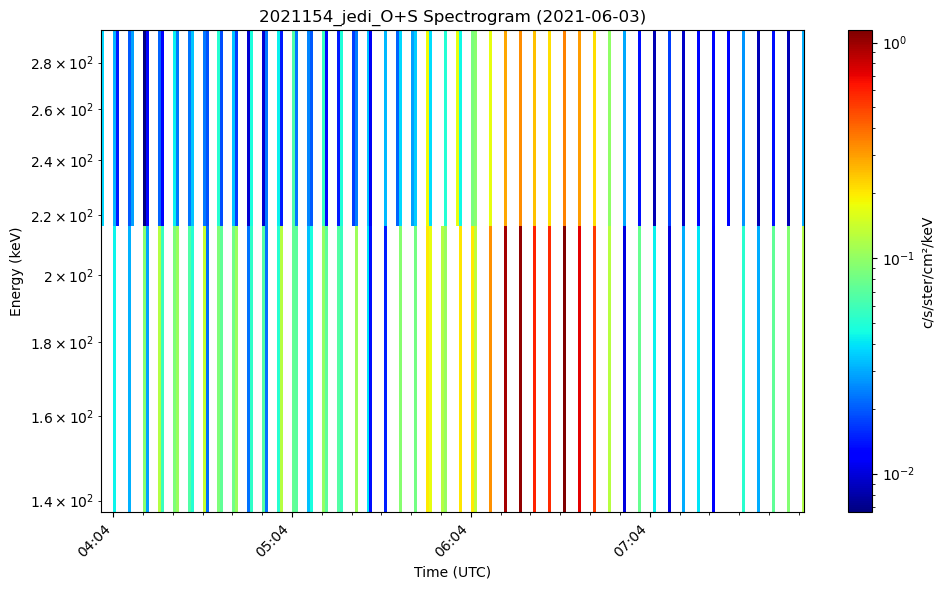

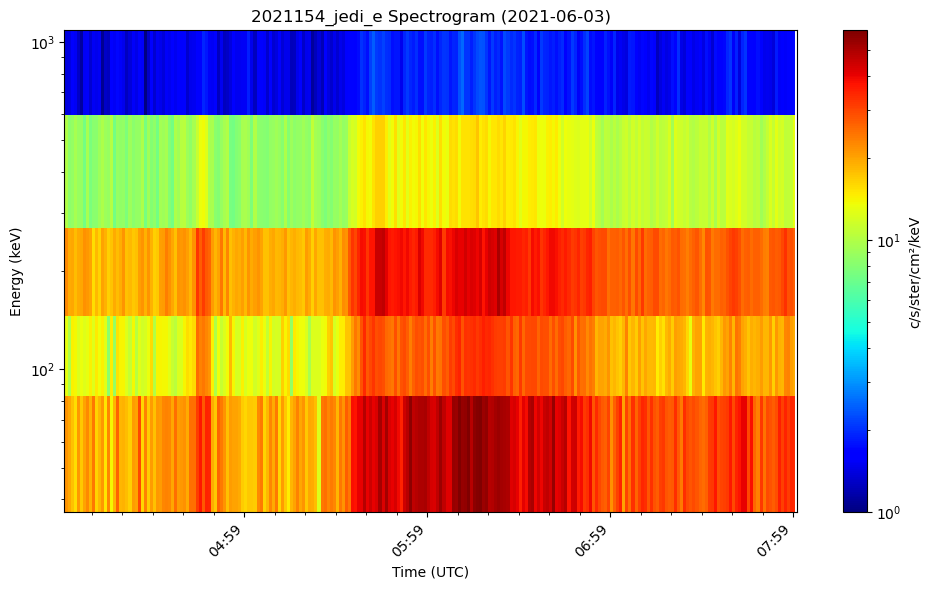

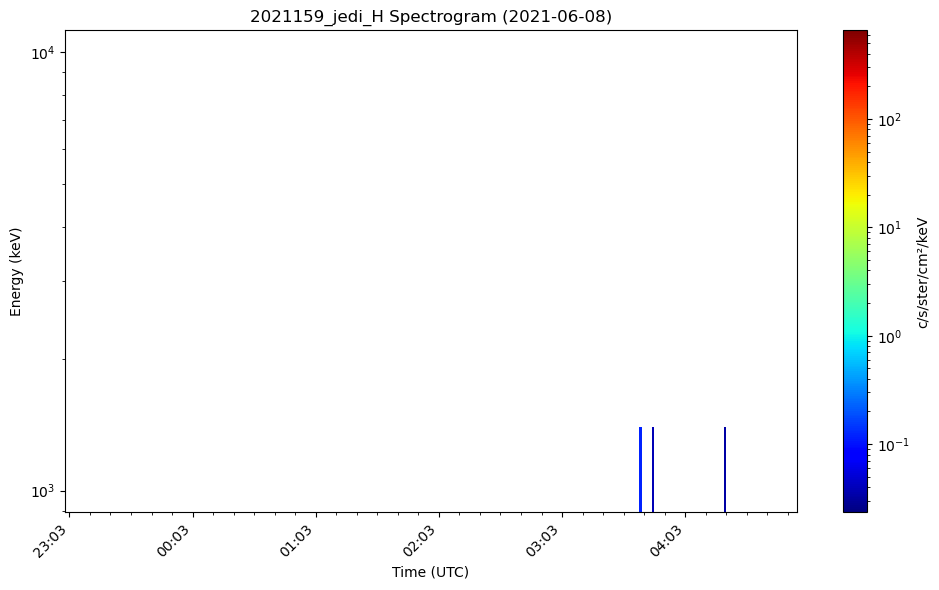

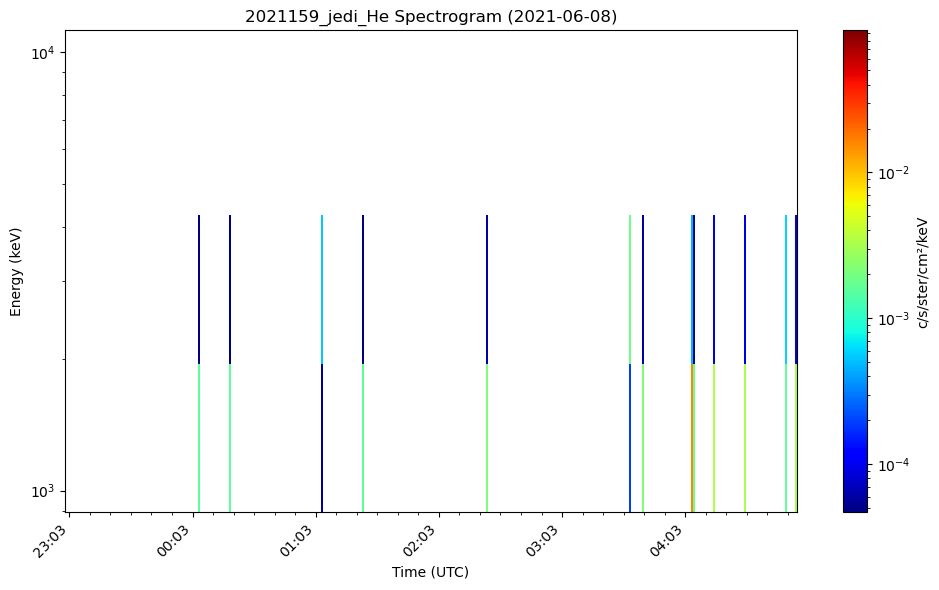

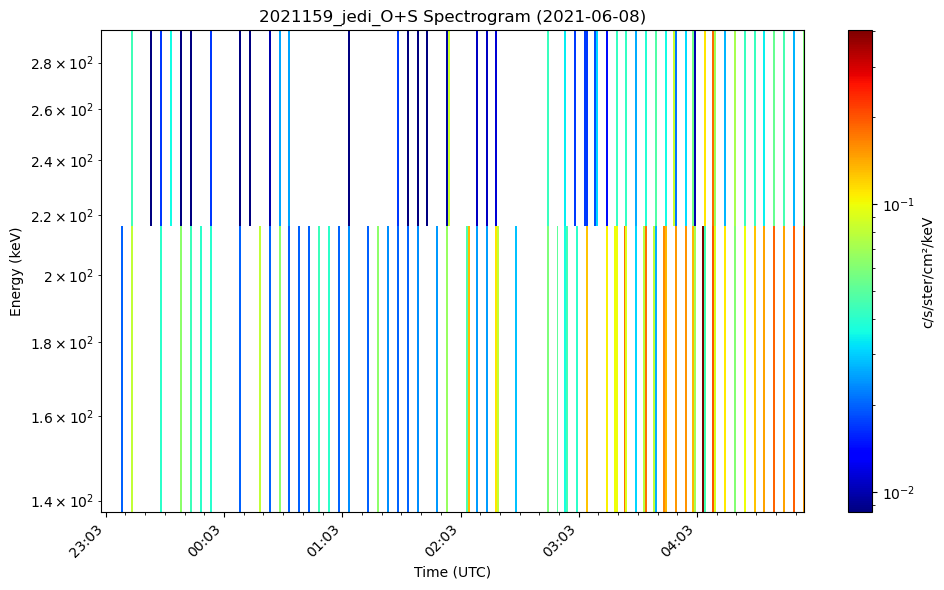

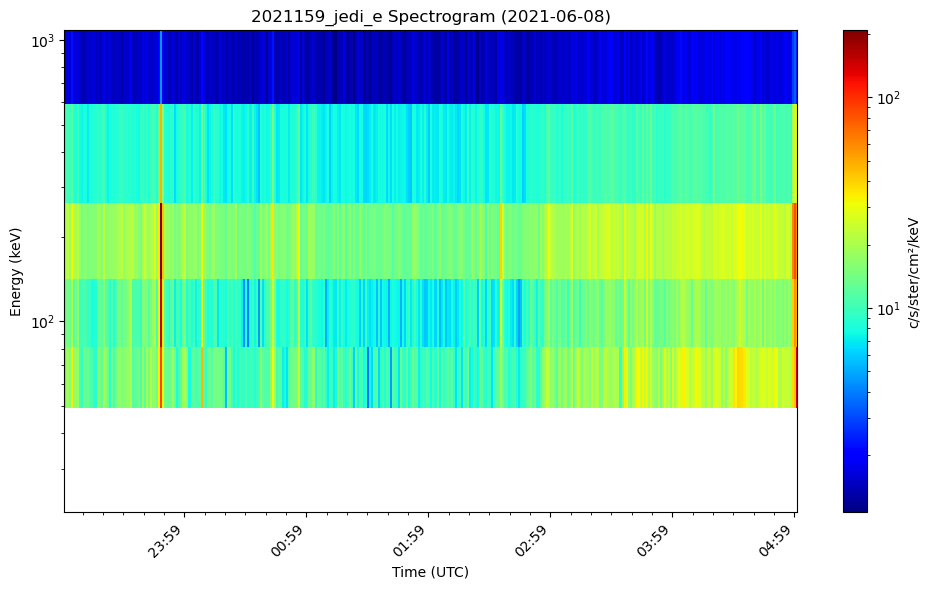

In [28]:
import glob
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates

# Directory containing your .d2s files
directory = 'Data_Files/Juno Data/Fenn'
pattern = os.path.join(directory, '*.d2s')

# Find and sort all .d2s files
files = sorted(glob.glob(pattern))

for fn in files:
    # 1) Read file
    with open(fn, 'r') as f:
        lines = f.readlines()
    # 2) Extract energy bins
    yt_line = next(l for l in lines if 'yTags=' in l)
    tags_str = re.search(r'yTags="([^"]+)"', yt_line).group(1)
    energies = np.array([float(x) for x in tags_str.split(',')])
    # 3) Parse data lines
    data_lines = [L for L in lines if L.startswith(':01:')]
    times = []
    values = []

    for L in data_lines:
        parts = L.strip().split()
        ts = parts[0][4:]
        times.append(pd.to_datetime(ts))
        values.append([float(x) for x in parts[1:]])
    # 4) Build arrays
    times = np.array(times, dtype='datetime64[ms]')
    spec  = np.array(values, dtype=float)
    # 5) Observation date for title
    obs_date = pd.to_datetime(times[0]).strftime('%Y-%m-%d')
    # 6) Plot spectrogram
    fig, ax = plt.subplots(figsize=(10,6))
    pcm = ax.pcolormesh(times, energies, spec.T,
                        norm=LogNorm(), cmap='jet', shading='auto')
    ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    ax.set_xlabel('Time (UTC)')
    ax.set_ylabel('Energy (keV)')
    ax.set_yscale('log')
    title_fn = os.path.basename(fn).replace('.d2s','')
    ax.set_title(f'{title_fn} Spectrogram ({obs_date})')
    cbar = fig.colorbar(pcm, ax=ax, label='c/s/ster/cm²/keV')
    plt.tight_layout()
    plt.show()


Saved plot to Segment Analysis Figures/2017192_jedi_H_spectrogram+LS.png


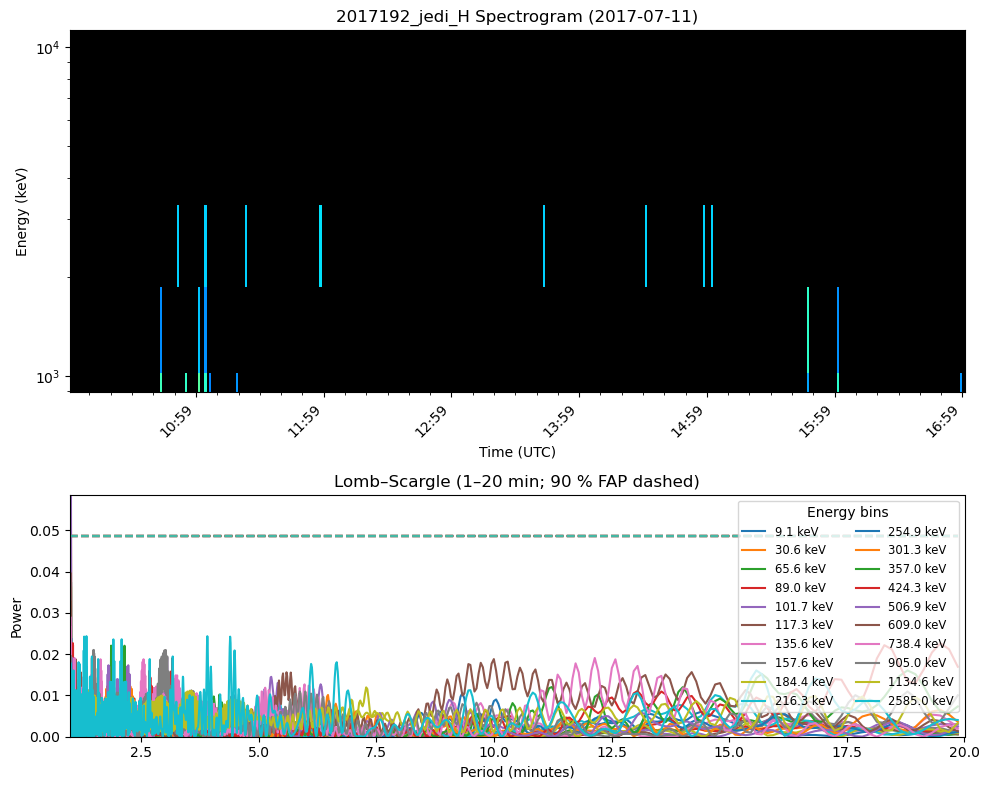

Saved plot to Segment Analysis Figures/2017192_jedi_He_spectrogram+LS.png


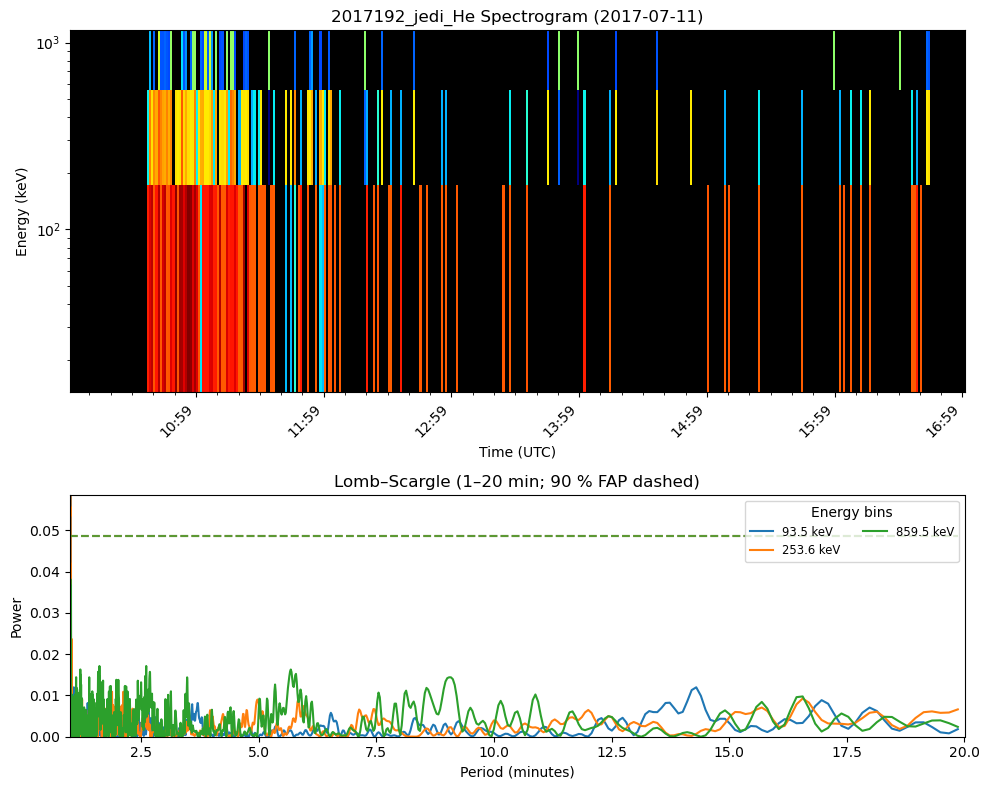

Saved plot to Segment Analysis Figures/2017192_jedi_O+S_spectrogram+LS.png


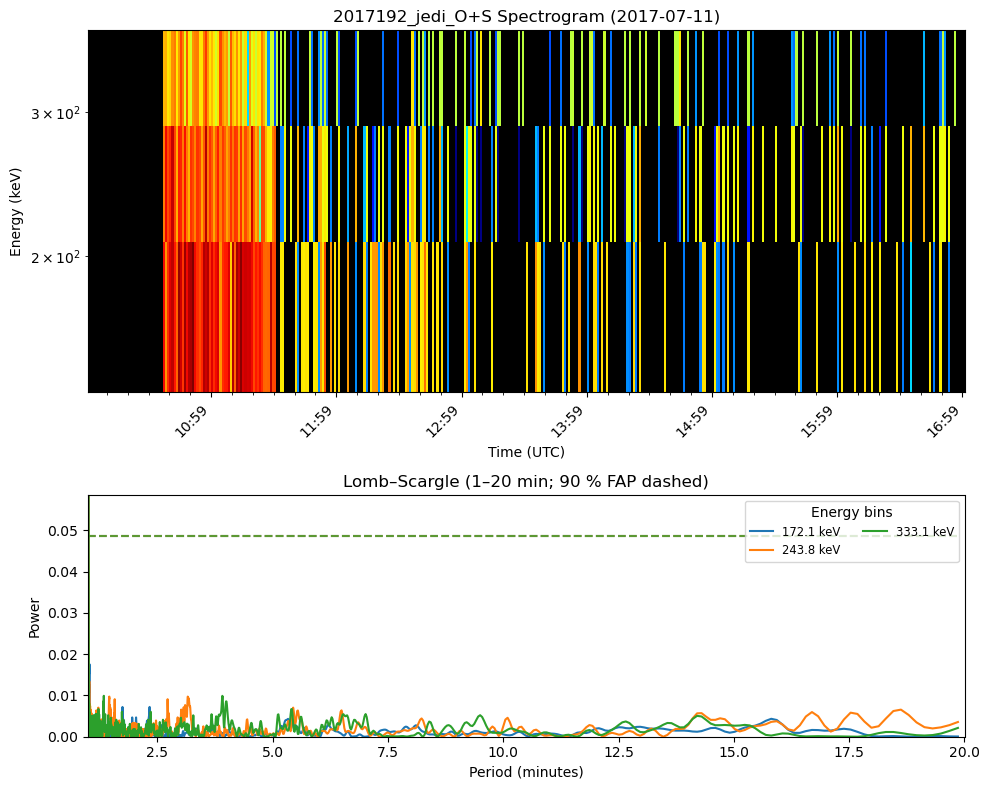

Saved plot to Segment Analysis Figures/2017192_jedi_e_spectrogram+LS.png


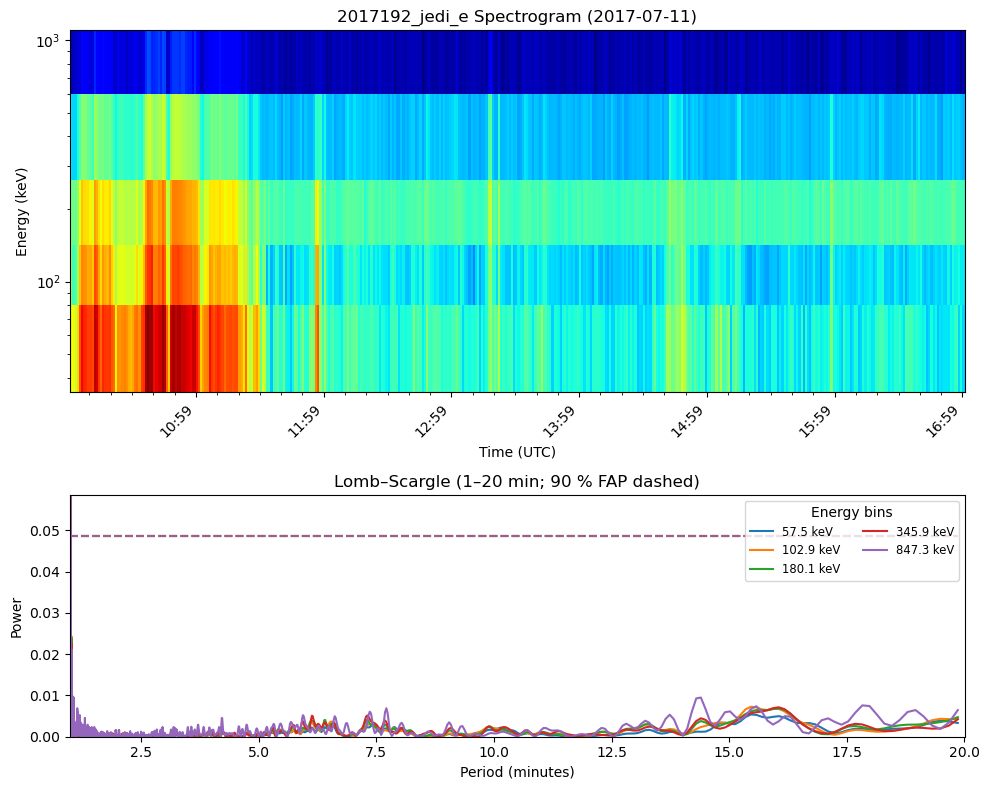

Saved plot to Segment Analysis Figures/2017197_jedi_H_spectrogram+LS.png


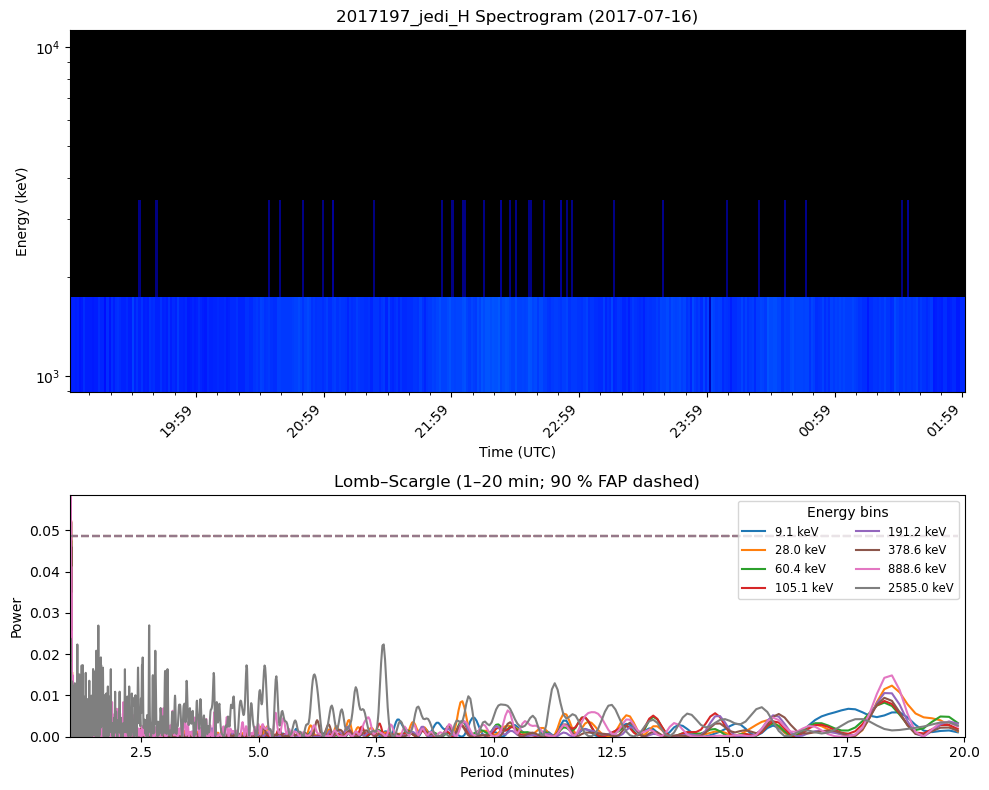

Saved plot to Segment Analysis Figures/2017197_jedi_He_spectrogram+LS.png


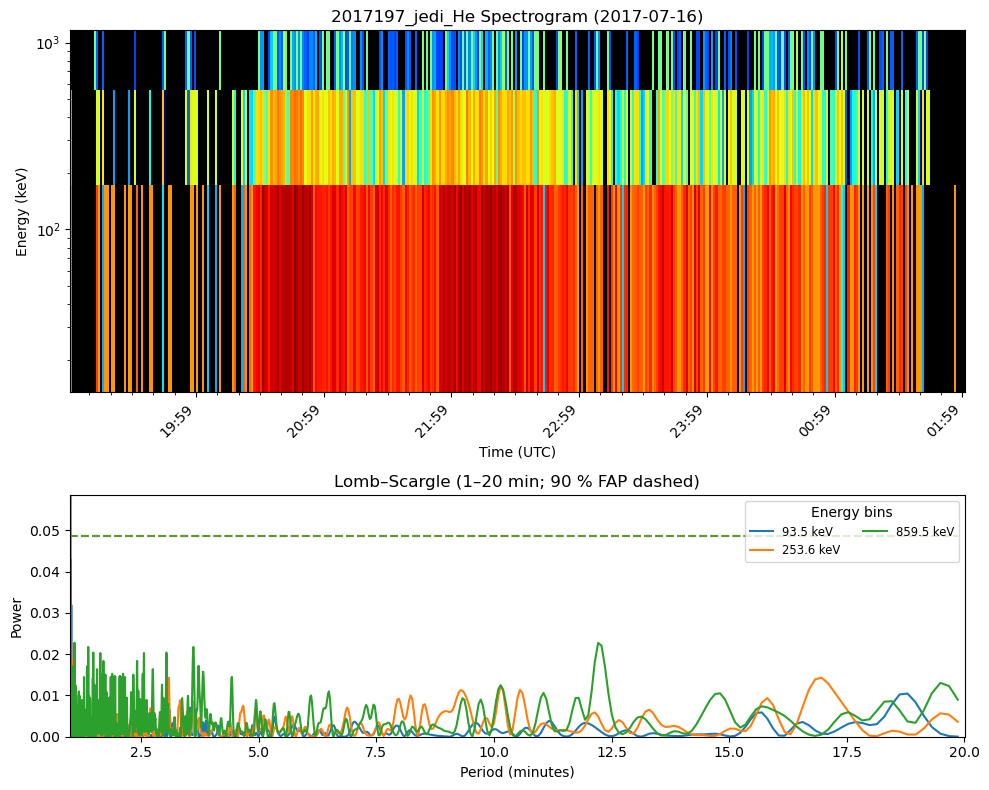

Saved plot to Segment Analysis Figures/2017197_jedi_O+S_spectrogram+LS.png


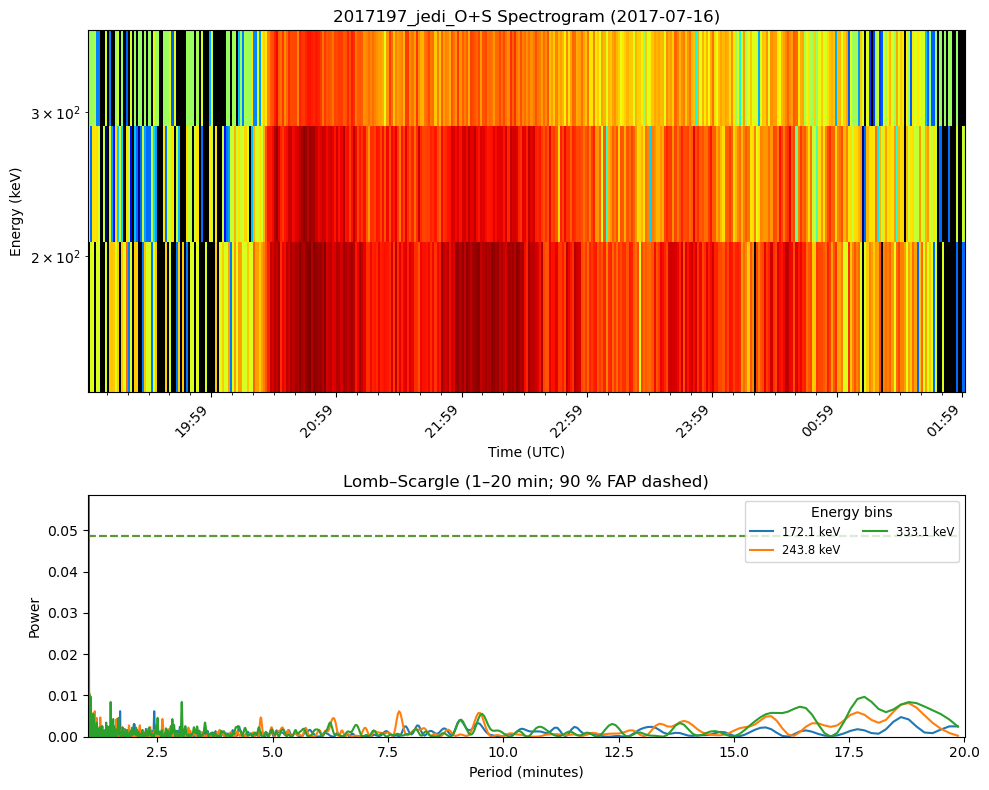

Saved plot to Segment Analysis Figures/2017197_jedi_e_spectrogram+LS.png


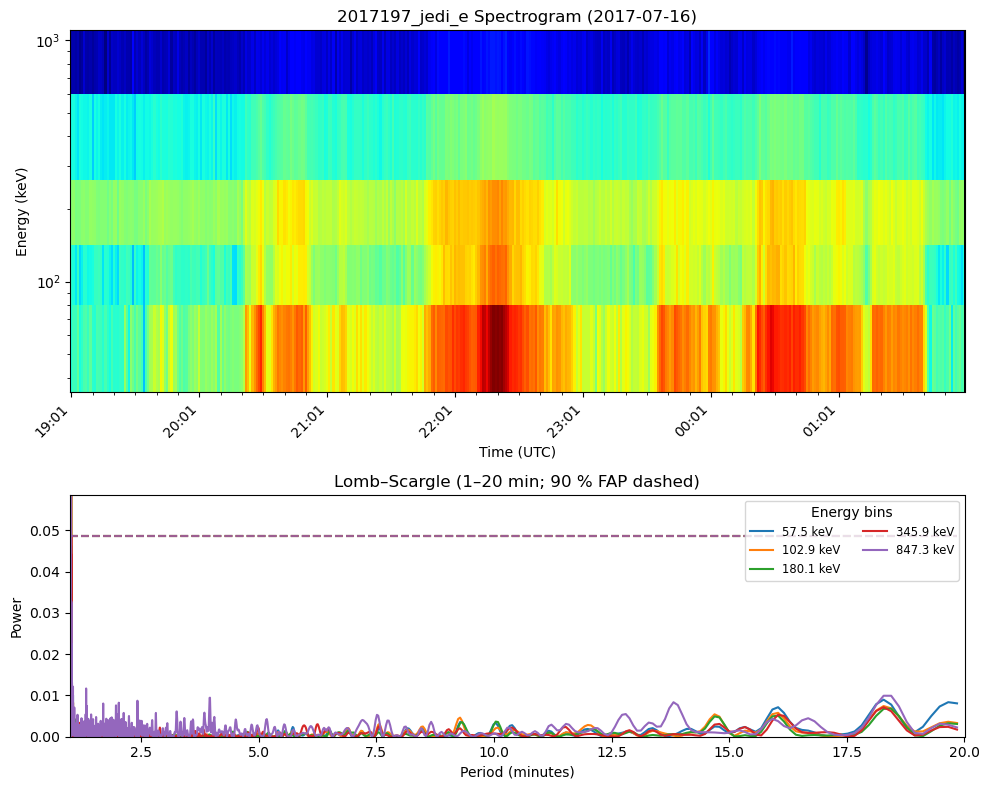

Saved plot to Segment Analysis Figures/2019092_jedi_H_spectrogram+LS.png


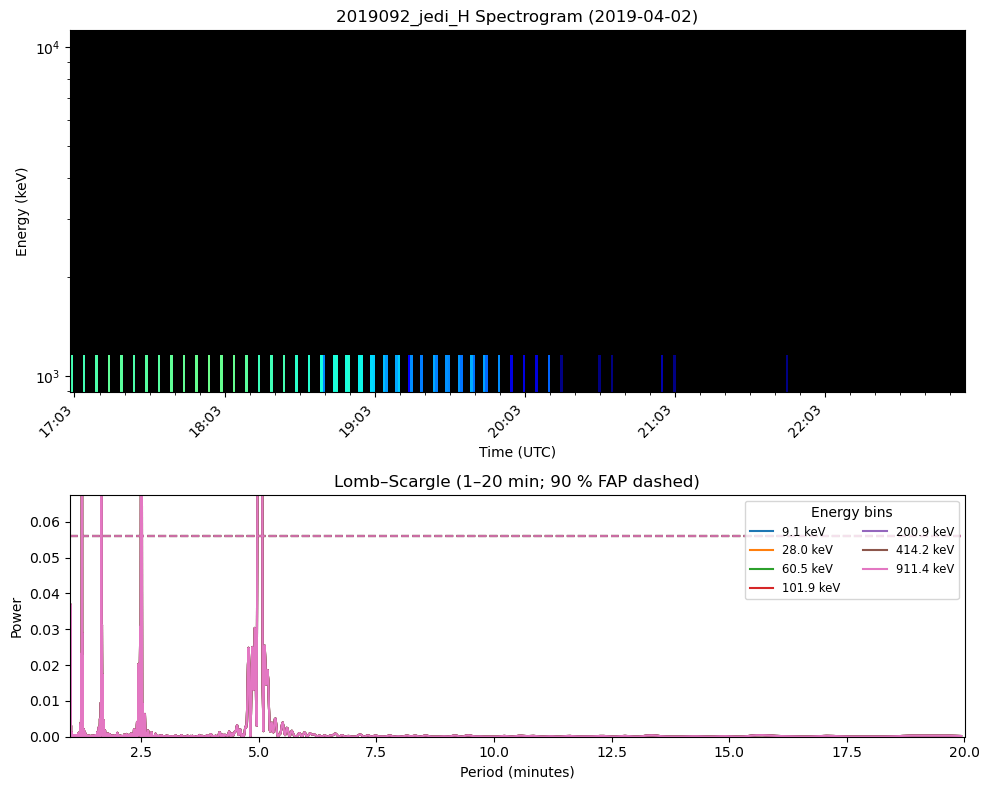

Saved plot to Segment Analysis Figures/2019092_jedi_He_spectrogram+LS.png


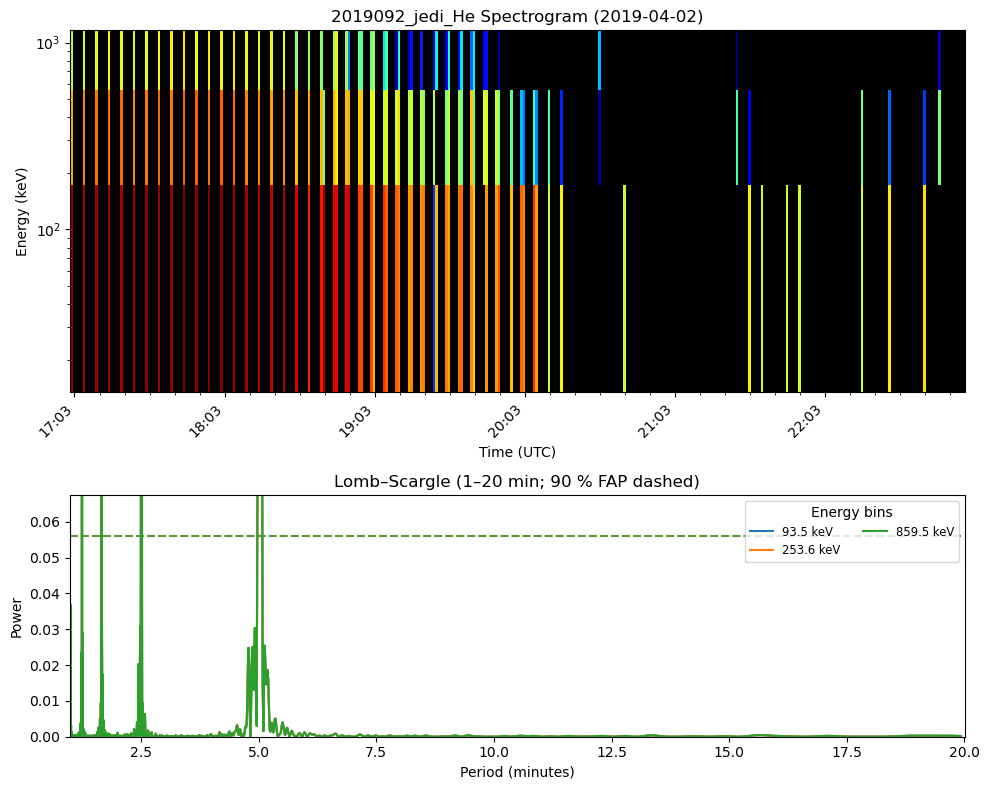

Saved plot to Segment Analysis Figures/2019092_jedi_O+S_spectrogram+LS.png


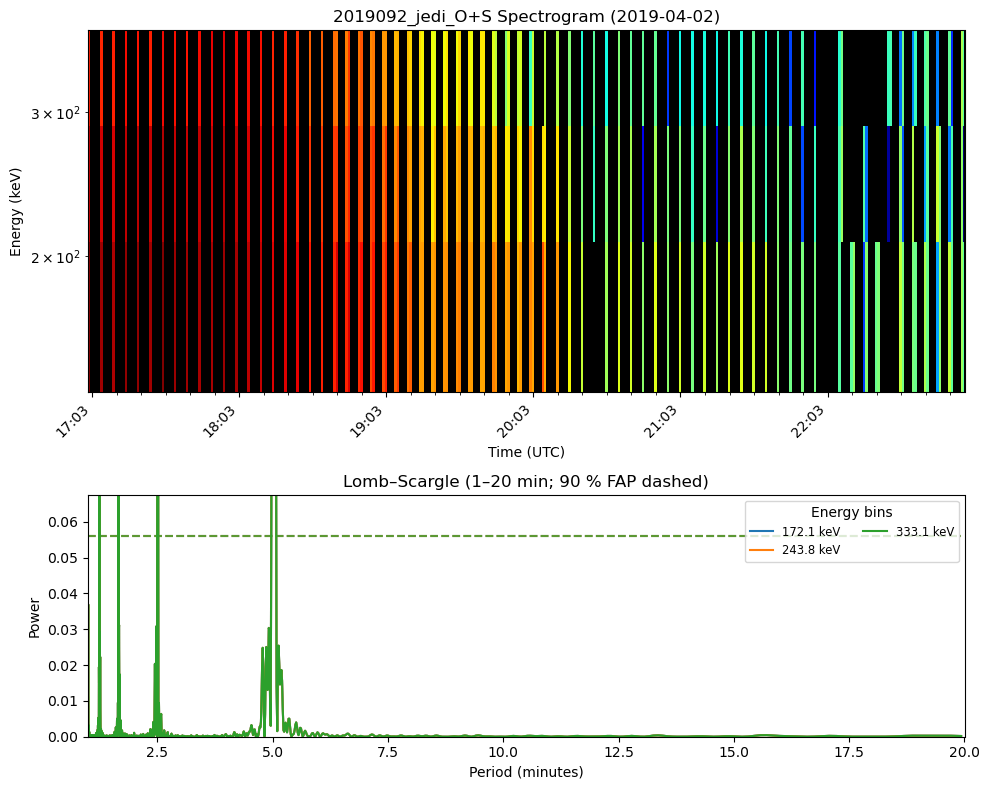

Saved plot to Segment Analysis Figures/2019092_jedi_e_spectrogram+LS.png


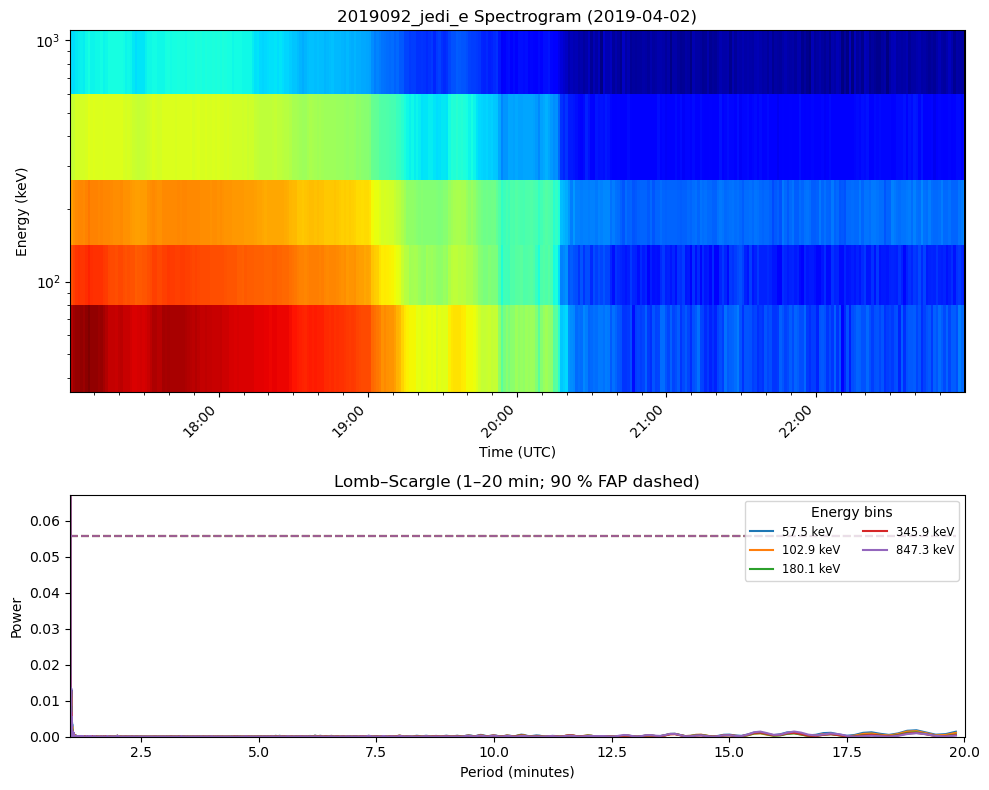

Saved plot to Segment Analysis Figures/2021153_jedi_H_spectrogram+LS.png


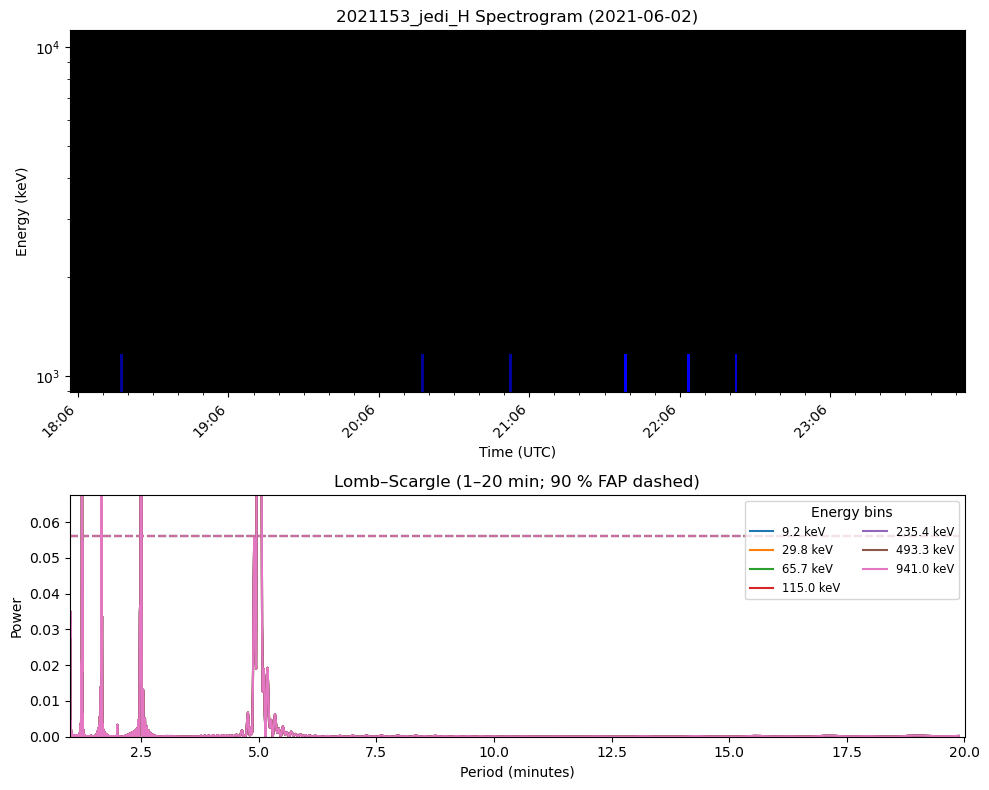

Saved plot to Segment Analysis Figures/2021153_jedi_He_spectrogram+LS.png


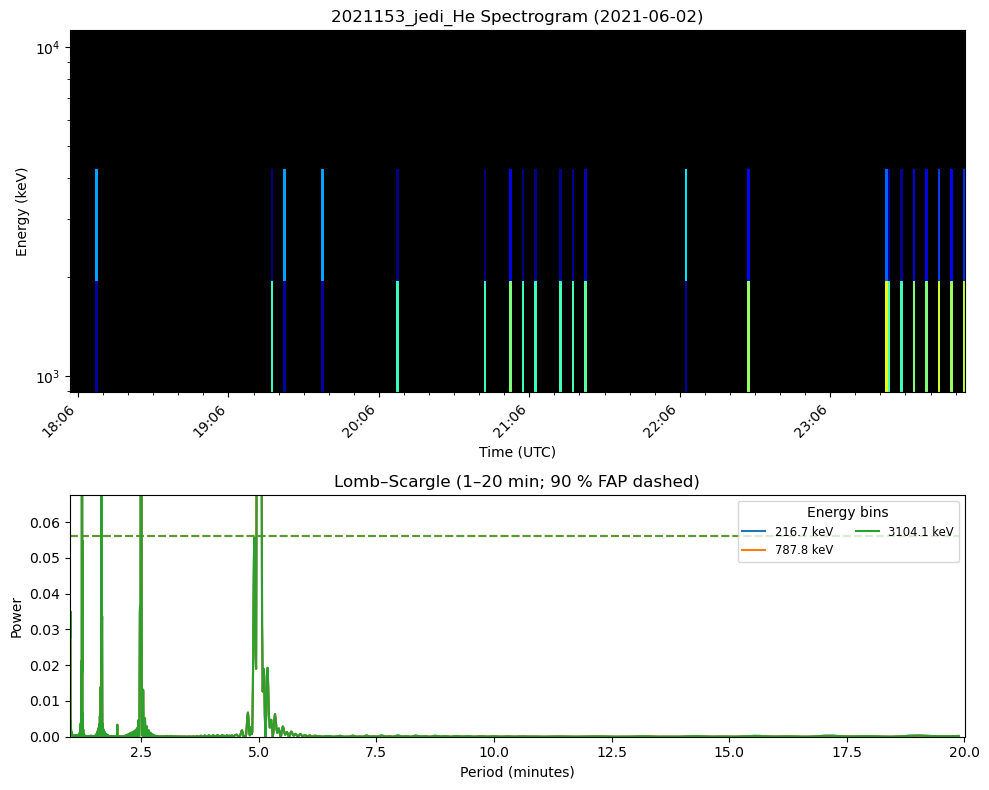

Saved plot to Segment Analysis Figures/2021153_jedi_O+S_spectrogram+LS.png


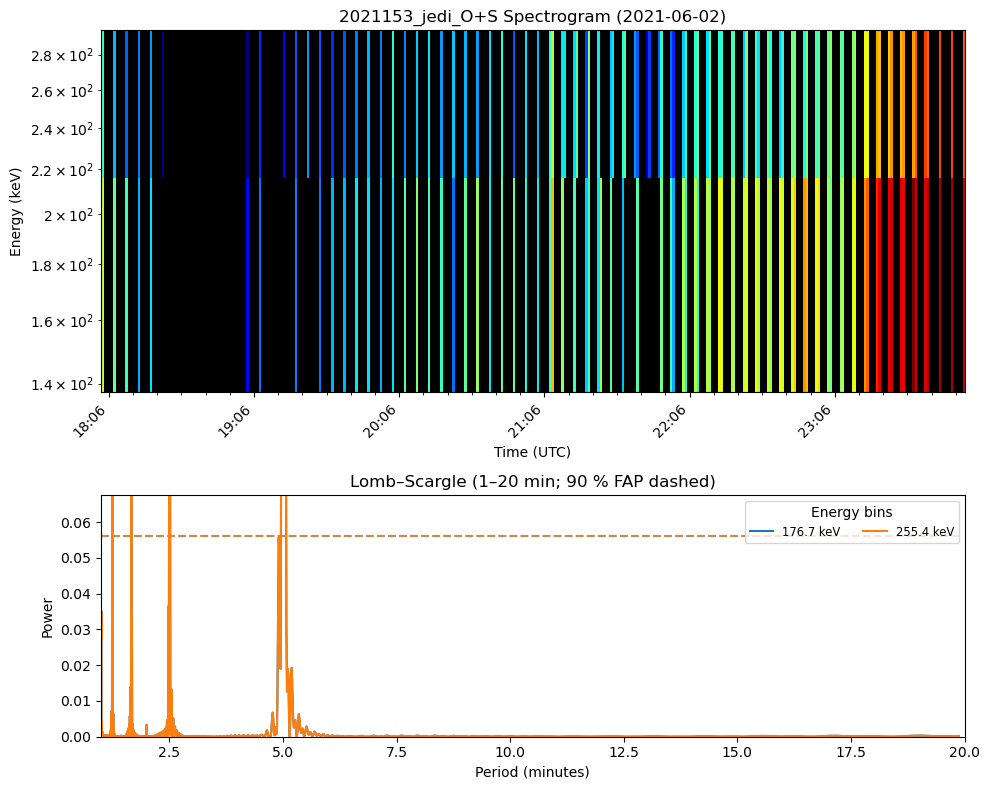

Saved plot to Segment Analysis Figures/2021153_jedi_e_spectrogram+LS.png


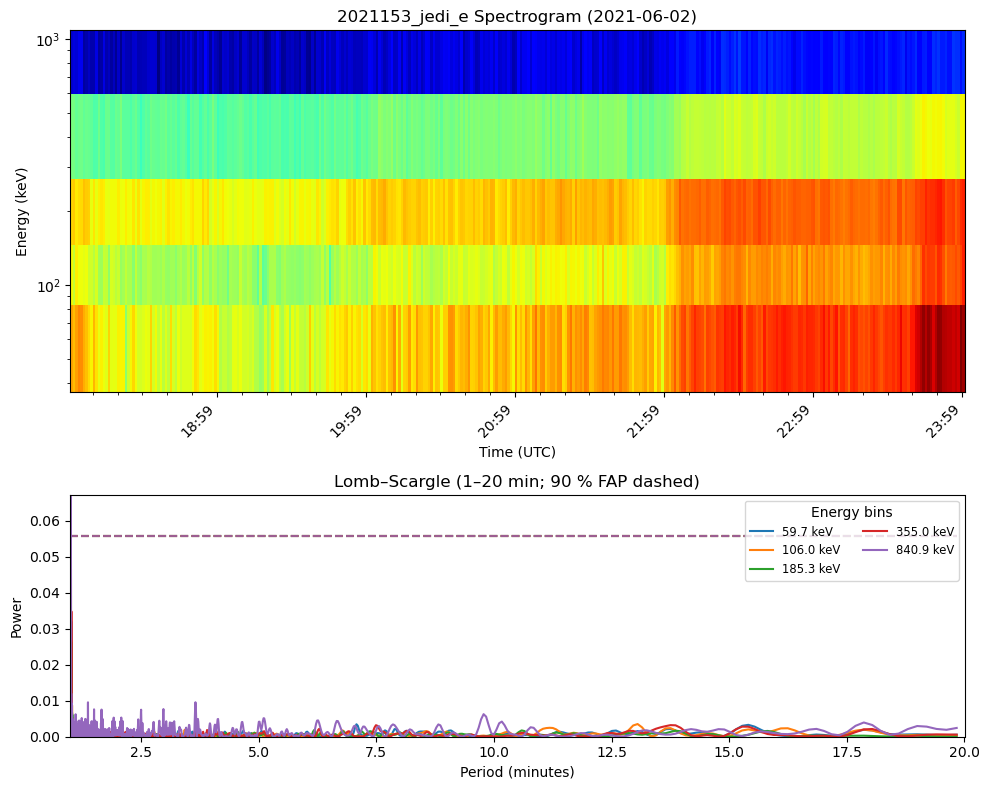

Saved plot to Segment Analysis Figures/2021154_jedi_H_spectrogram+LS.png


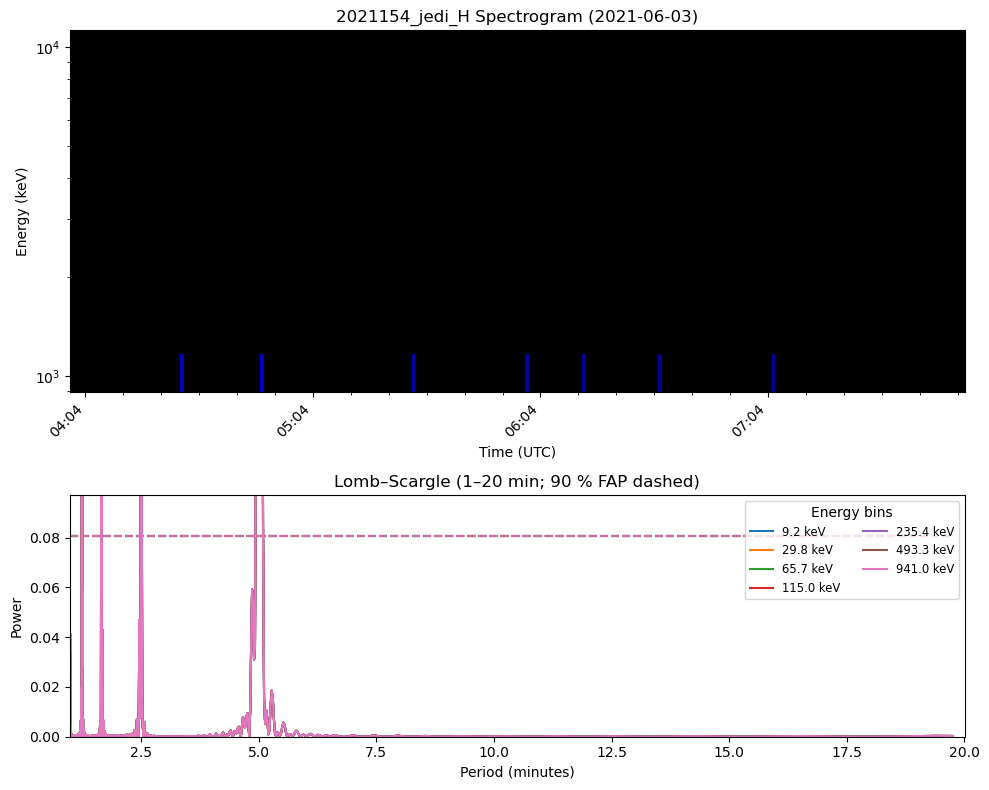

Saved plot to Segment Analysis Figures/2021154_jedi_He_spectrogram+LS.png


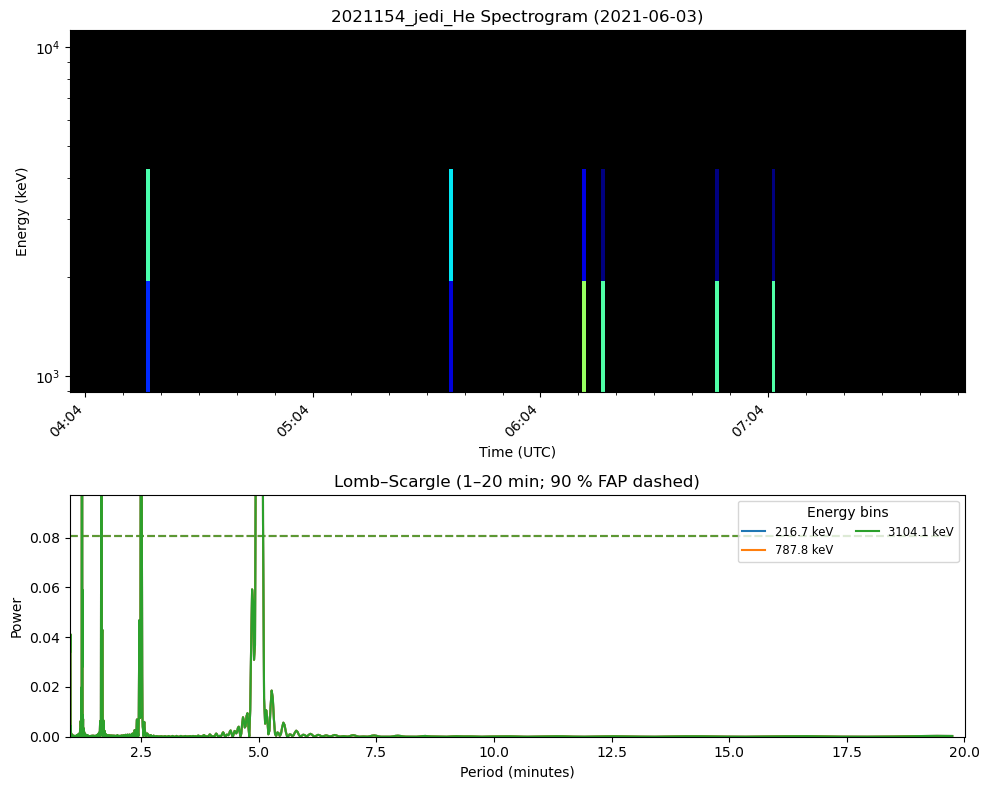

Saved plot to Segment Analysis Figures/2021154_jedi_O+S_spectrogram+LS.png


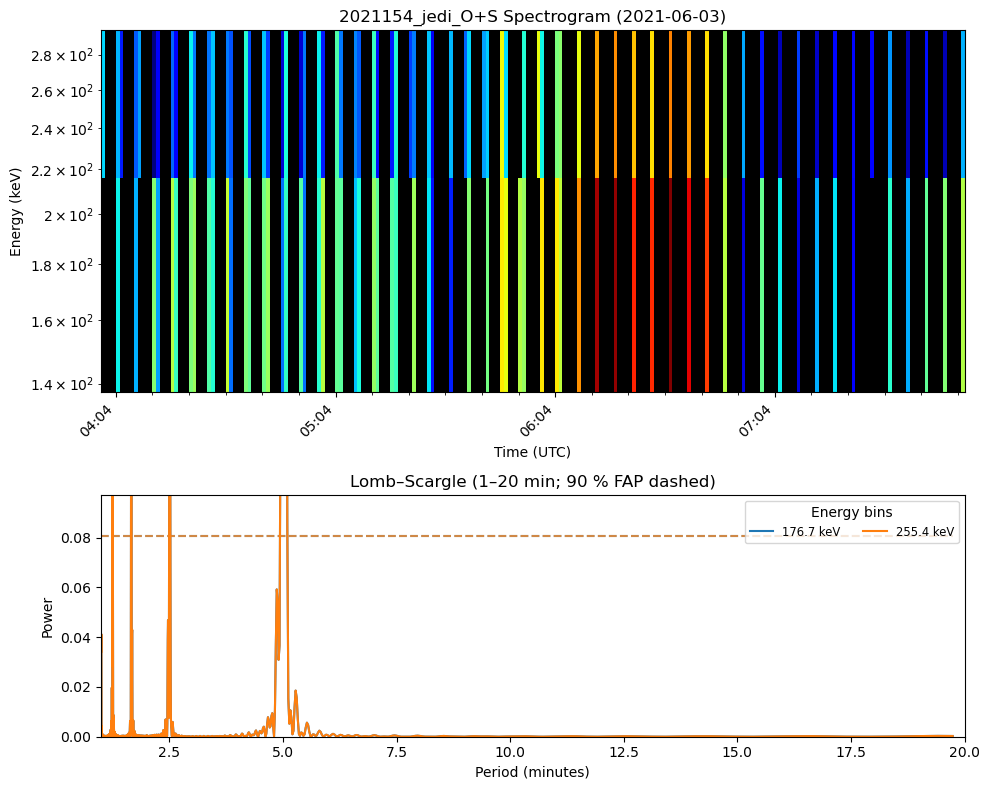

Saved plot to Segment Analysis Figures/2021154_jedi_e_spectrogram+LS.png


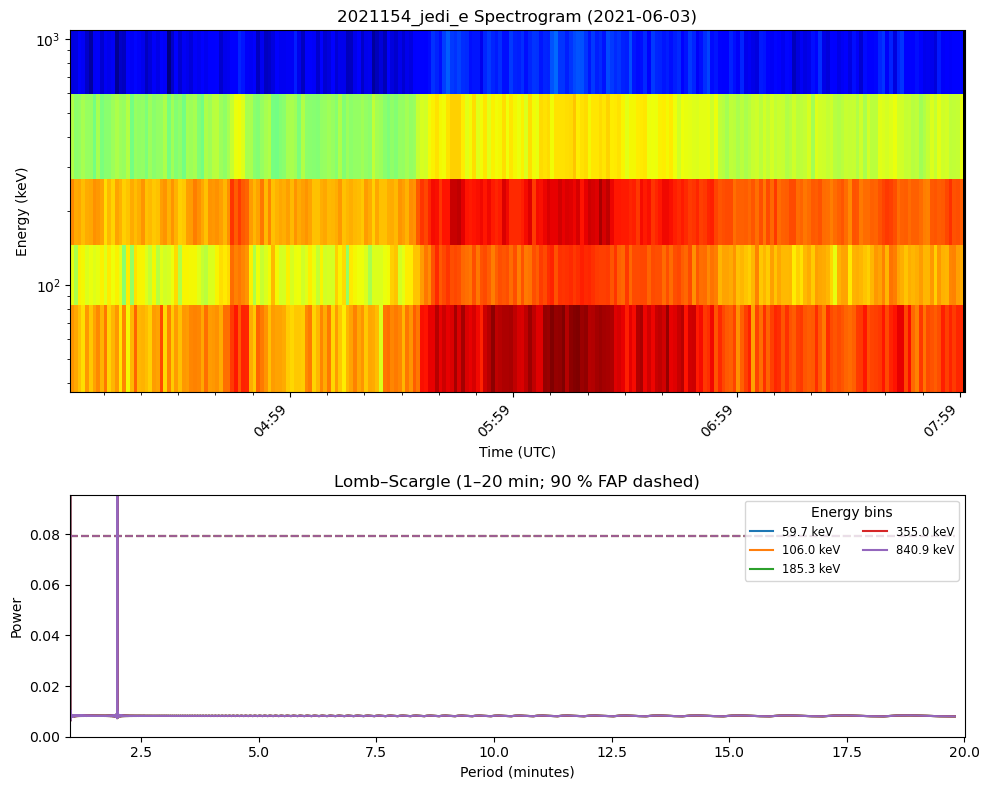

Saved plot to Segment Analysis Figures/2021159_jedi_H_spectrogram+LS.png


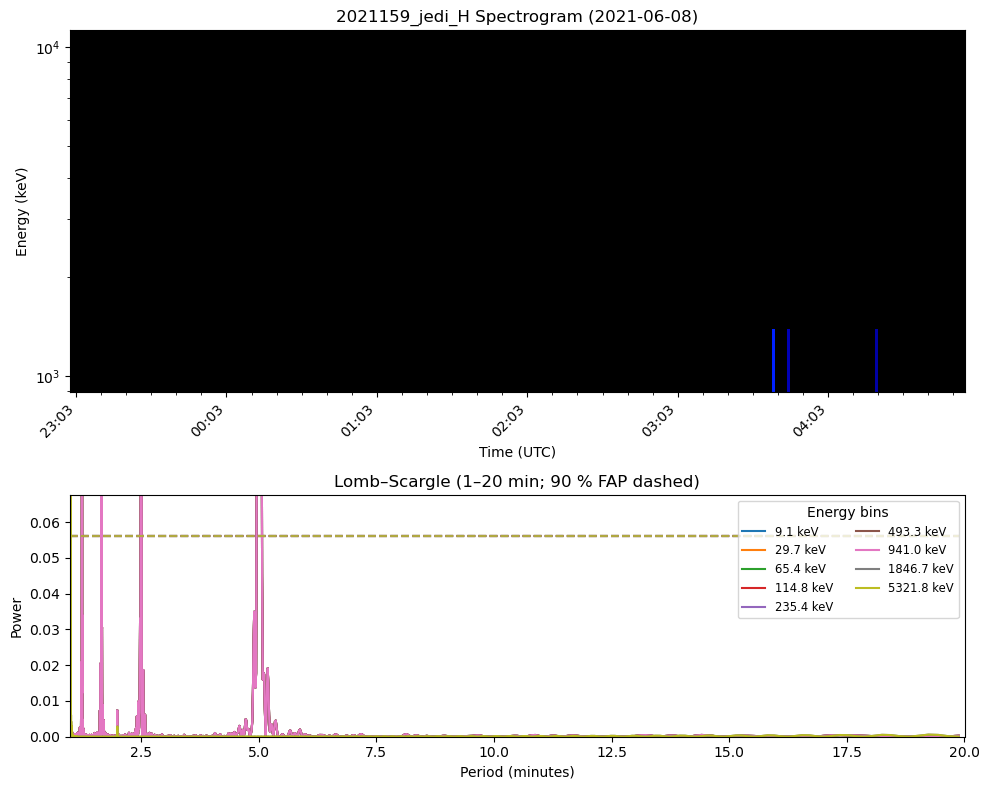

Saved plot to Segment Analysis Figures/2021159_jedi_He_spectrogram+LS.png


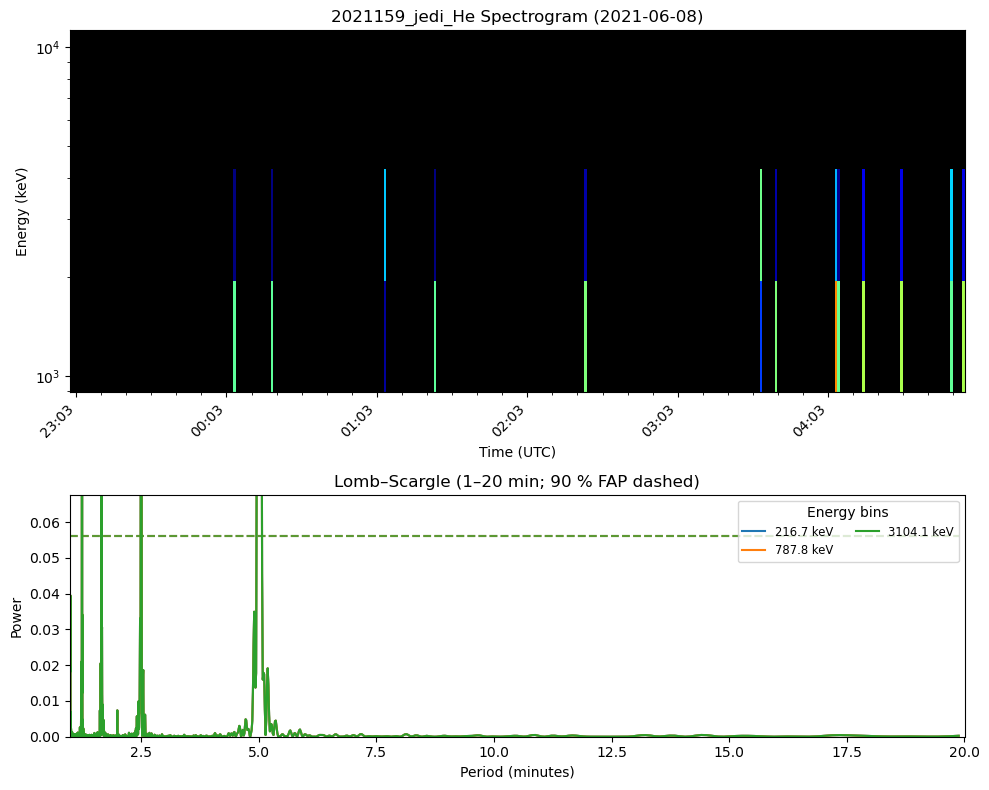

Saved plot to Segment Analysis Figures/2021159_jedi_O+S_spectrogram+LS.png


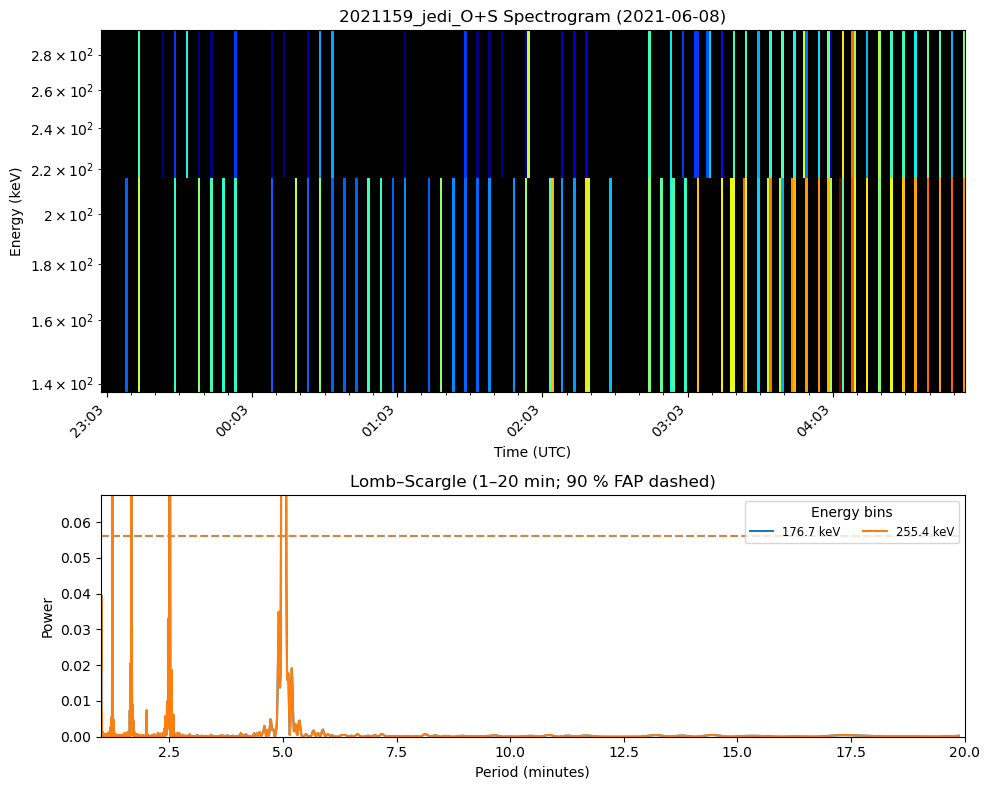

Saved plot to Segment Analysis Figures/2021159_jedi_e_spectrogram+LS.png


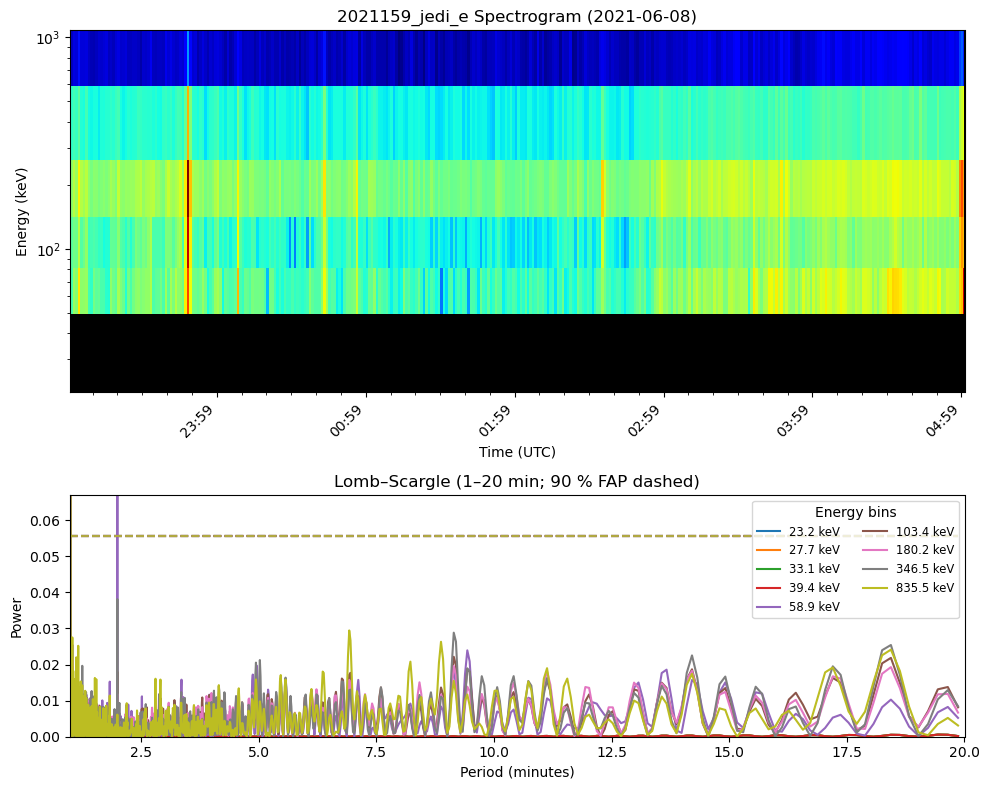

In [40]:
import glob
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates
from astropy.timeseries import LombScargle

# Directory containing your .d2s files
directory = 'Data_Files/Juno Data/Fenn'
pattern   = os.path.join(directory, '*.d2s')
files     = sorted(glob.glob(pattern))

for fn in files:
    # 1) Read file
    with open(fn, 'r') as f:
        lines = f.readlines()

    # 2) Extract energy bins
    yt_line  = next(l for l in lines if 'yTags=' in l)
    tags_str = re.search(r'yTags="([^"]+)"', yt_line).group(1)
    energies = np.array([float(x) for x in tags_str.split(',')])

    # 3) Parse data lines
    data_lines = [L for L in lines if L.startswith(':01:')]
    times = []
    values = []
    for L in data_lines:
        parts = L.strip().split()
        ts = parts[0][4:]
        times.append(pd.to_datetime(ts))
        values.append([float(x) for x in parts[1:]])

    # 4) Build arrays
    times = np.array(times, dtype='datetime64[ms]')
    spec  = np.array(values, dtype=float)

    # convert times to seconds since start
    t_sec = (times - times[0]) / np.timedelta64(1, 's')

    # 5) Observation date & title
    obs_date = pd.to_datetime(times[0]).strftime('%Y-%m-%d')
    title_fn = os.path.basename(fn).replace('.d2s','')

    # 6) Two‐panel figure: spectrogram above, LS below
    fig, (ax_spec, ax_ls) = plt.subplots(
        2, 1,
        figsize=(10,8),
        gridspec_kw={'height_ratios': [3, 2]}
    )

    # Top: Spectrogram
    pcm = ax_spec.pcolormesh(
        times, energies, spec.T,
        norm=LogNorm(), cmap='jet', shading='auto'
    )
    ax_spec.set_yscale('log')
    ax_spec.set_facecolor('black') 
    ax_spec.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))
    ax_spec.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax_spec.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
    plt.setp(ax_spec.xaxis.get_majorticklabels(), rotation=45, ha='right')
    ax_spec.set_xlabel('Time (UTC)')
    ax_spec.set_ylabel('Energy (keV)')
    ax_spec.set_title(f'{title_fn} Spectrogram ({obs_date})')
    #fig.colorbar(pcm, ax=ax_spec, label='c/s/ster/cm²/keV')

    # Bottom: Lomb–Scargle periodograms (1–20 min)
    colors  = plt.cm.tab10.colors
    n_bins  = spec.shape[1]
    max_fap = 0.0

    for i in range(n_bins):
        y = spec[:, i]
        mask = np.isfinite(y)
        if mask.sum() < 3:
            continue

        ls = LombScargle(t_sec[mask], y[mask])
        freq, power = ls.autopower()

        # convert to period (min) and mask to 1–20 min
        period = 1.0 / freq / 60.0
        ok     = (period >= 1) & (period <= 20)
        period = period[ok]
        power  = power[ok]

        # 90% false‐alarm level
        fap90 = ls.false_alarm_level(0.1)
        max_fap = max(max_fap, fap90)

        col = colors[i % len(colors)]
        ax_ls.plot(period, power,
                   color=col,
                   label=f'{energies[i]:.1f} keV')
        ax_ls.hlines(fap90,
                     xmin=period.min(),
                     xmax=period.max(),
                     color=col,
                     linestyle='--',
                     alpha=0.7)

    # Set y‐limit to 1.2× highest FAP
    ax_ls.set_ylim(0, top=1.2 * max_fap)

    ax_ls.set_xlabel('Period (minutes)')
    ax_ls.set_ylabel('Power')
    ax_ls.set_xlim(1, 20)
    ax_ls.set_title('Lomb–Scargle (1–20 min; 90 % FAP dashed)')
    ax_ls.legend(ncol=2,
                 fontsize='small',
                 loc='upper right',
                 title='Energy bins')

    plt.tight_layout()
    save_name = f"{title_fn}_spectrogram+LS.png"
    save_path = os.path.join('Segment Analysis Figures', save_name)
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved plot to {save_path}")
    plt.show()

['2019-04-02T17:00:22.000' '2019-04-02T17:00:52.000'
 '2019-04-02T17:01:22.000' '2019-04-02T17:01:52.000'
 '2019-04-02T17:02:22.000' '2019-04-02T17:02:52.000'
 '2019-04-02T17:03:22.000' '2019-04-02T17:03:52.000'
 '2019-04-02T17:04:22.000' '2019-04-02T17:04:52.000'
 '2019-04-02T17:05:22.000' '2019-04-02T17:05:52.000'
 '2019-04-02T17:06:22.000' '2019-04-02T17:06:52.000'
 '2019-04-02T17:07:22.000' '2019-04-02T17:07:52.000'
 '2019-04-02T17:08:22.000' '2019-04-02T17:08:52.000'
 '2019-04-02T17:09:22.000' '2019-04-02T17:09:52.000'
 '2019-04-02T17:10:22.000' '2019-04-02T17:10:52.000'
 '2019-04-02T17:11:22.000' '2019-04-02T17:11:52.000'
 '2019-04-02T17:12:22.000' '2019-04-02T17:12:52.000'
 '2019-04-02T17:13:22.000' '2019-04-02T17:13:52.000'
 '2019-04-02T17:14:22.000' '2019-04-02T17:14:52.000'
 '2019-04-02T17:15:22.000' '2019-04-02T17:15:52.000'
 '2019-04-02T17:16:22.000' '2019-04-02T17:16:52.000'
 '2019-04-02T17:17:22.000' '2019-04-02T17:17:52.000'
 '2019-04-02T17:18:22.000' '2019-04-02T17:18:5

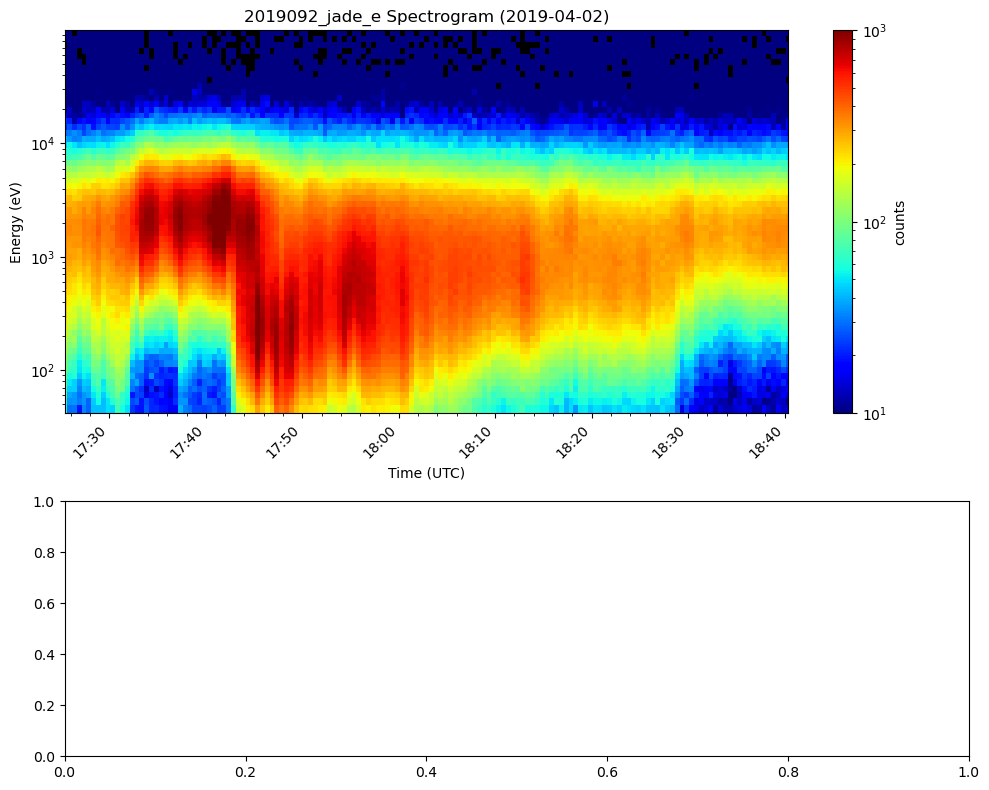

In [54]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates
from astropy.timeseries import LombScargle

# Directory containing your JADE .txt files
directory = 'Data_Files/Juno Data/Fenn'    # adjust as needed
pattern   = os.path.join(directory, '*.txt')
#files     = sorted(glob.glob(pattern))
files = ['Data_Files/Juno Data/Fenn/2019092_jade_e.txt']
for fn in files:
    # --- 1) Read entire file
    with open(fn, 'r') as f:
        lines = f.readlines()

    # --- 2) Extract energy bins from header
    header = next(l for l in lines if l.lstrip().startswith('#'))
    tokens = header.strip().split()
    idx = tokens.index('(eV)')
    energies = np.array([float(x) for x in tokens[idx+1:]])

    # --- 3) Parse data lines (skip any line starting with "#")
    times = []
    values = []
    for L in lines:
        if L.lstrip().startswith('#') or not L.strip():
            continue
        cols = L.strip().split()
        # first column is timestamp like "2017-07-11/11:00:23"
        tstr = cols[0]
        times.append(pd.to_datetime(tstr, format='%Y-%m-%d/%H:%M:%S'))
        # the rest are floats
        values.append([float(x) for x in cols[1:]])

    # --- 4) Build arrays
    times = np.array(times, dtype='datetime64[ms]')
    spec  = np.array(values, dtype=float)
    print(times)
    # --- 5) Seconds since start (for LS)
    t_sec = (times - times[0]) / np.timedelta64(1, 's')

    # --- 6) Prepare figure & axes
    obs_date = pd.to_datetime(times[0]).strftime('%Y-%m-%d')
    title_fn = os.path.basename(fn).replace('.txt','')
    fig, (ax_spec, ax_ls) = plt.subplots(
        2, 1, figsize=(10,8),
        gridspec_kw={'height_ratios': [3, 2]}
    )

    # ---- a) Top panel: spectrogram
    pcm = ax_spec.pcolormesh(
        times, energies, spec.T,
        norm=LogNorm(vmin=1e1, vmax=1e3), cmap='jet', shading='auto'
    )
    ax_spec.set_yscale('log')
    ax_spec.set_facecolor('black') 
    ax_spec.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
    ax_spec.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax_spec.xaxis.set_minor_locator(mdates.MinuteLocator(interval=2))
    plt.setp(ax_spec.xaxis.get_majorticklabels(), rotation=45, ha='right')
    ax_spec.set_xlabel('Time (UTC)')
    ax_spec.set_ylabel('Energy (eV)')
    ax_spec.set_title(f'{title_fn} Spectrogram ({obs_date})')
    ax_spec.set_xlim(times[50], times[200])
    fig.colorbar(pcm, ax=ax_spec, label='counts')

    
    plt.tight_layout()
    save_name = f"{title_fn}_spectrogram+LS.png"
    save_path = os.path.join('Segment Analysis Figures', save_name)
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved plot to {save_path}")
    plt.show()
